# na-VGWP examples

Runs the five `examples/0*.py` scripts as notebook cases, on top of the
reorganised package layout:

    navgwp2/
        __init__.py
        compute.py      Gaussian toolbox, equations of motion, run(), observables, exact reference
                        (one engine; every Gaussian carries a full D x D complex width matrix)
        initialize.py   model builders (tully1, fmo, holstein_ref, lvc, ...) and initial conditions
        plot.py         figures
        save.py         p/q/a/coeff/wfc text output, pickle, CSV

Structure of this notebook, one case at a time:

1. `case = <n>` selects the example.
2. Every definition lives in **`examples/model.py`**, imported as `mdl`
   (not `model`, which is the name used below for the built model dict).
   The cells call it rather than declaring anything:
   `mdl.model_params(case)`, `mdl.dyn_params(case, model_params)`,
   `mdl.plot_params(case)` and `mdl.build_model(model_params)`, which
   dispatches a numeric `"model"` id to the matching `initialize.*` builder.
   Edit `model.py`, then re-run the `importlib.reload(mdl)` cell -- no kernel
   restart needed.
3. **One engine.** `navgwp2.compute` gives every state a full D x D complex
   width matrix, so the packets may tilt; `dyn_params` therefore always
   carries `Z0` and `width_shape="full"`. Separable diabats (Tully I/II) and
   `quad_coupling` (Tully III) are supported here too, so no case is
   excluded. For the D=1 cases the matrix is 1x1 and identical to a per-mode
   width; only case 5 (Ferretti, D=2) actually tilts.
4. **Build & plot surfaces** -- builds the model(s) and calls
   `plot.plot_potentials(model)` to show the PES before any dynamics run.
5. **Run the dynamics** -- propagates via `mdl.run_case()`, and writes every
   recorded observable as plain text into `mdl.outdir_for(case)` with
   `mdl.write_observables()`: `summary.txt` (scalars), `observables.txt`
   (t, energy, norm, populations, and q/p/widths per state and mode),
   `widths_full.txt` (the full Z), and the Libra-style
   `q/p/a/coeff/wfc.txt`. Read any of them back with
   `mdl.read_observables(path)`.
6. **Plot populations**, **7. Plot summary (4-panel diagnostics)** and
   **8. Plot density snapshots**, each its own cell dispatching on `case`.
   The density cell builds a `wfc_plt_params` dict and passes it to
   `plot.plot_density_grid`; for D=2 it also calls
   `mdl.plot_density_2d_full`, which keeps the off-diagonal of the width
   matrix and so draws a tilted packet tilted (`plot.plot_density_2d`
   assumes that off-diagonal is zero).

Tip: after changing `case`, re-run all the cells from the `case = ...` cell
down (or Kernel > Restart & Run All) so nothing from a previous case lingers.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # examples/ -> navgwp_v2/ (package root)
sys.path.insert(0, os.path.abspath("."))    # so `import model` finds examples/model.py

import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt

from navgwp2 import initialize, compute, plot, save

# model.py holds every case definition, the run/observable helpers and the
# tilt-aware density plot.  Imported as `mdl` because `model` is the name this
# notebook uses for the built model dict.
import model as mdl

In [2]:
# Everything that used to be defined inline here now lives in examples/model.py:
#
#   mdl.BUILDER_*            numeric model ids
#   mdl.build_model(params)  dispatch a case to its initialize.* builder
#   mdl.model_params(case)   / mdl.dyn_params(case, mp) / mdl.plot_params(case)
#   mdl.run_case(...)        propagate (one engine, full D x D width matrix)
#   mdl.exact_steps(...)     step cap for the split-operator reference
#   mdl.write_observables(...) / mdl.read_observables(...)   text output
#   mdl.plot_density_2d_full(...)  2-D density that keeps the width tilt
#
# Reload the package and model.py after editing them, without restarting the
# kernel (package modules first: model.py imports them):
import importlib
import navgwp2
for _m in (initialize, compute, plot, save):
    importlib.reload(_m)
importlib.reload(navgwp2)
importlib.reload(mdl)

print([n for n in mdl.__all__ if not n.startswith("BUILDER")])

['CASES', 'MAX_EXACT_STEPS', 'build_model', 'model_params', 'dyn_params', 'plot_params', 'outdir_for', 'exact_steps', 'run_case', 'write_table', 'write_observables', 'read_observables', 'density_2d', 'density_axis_range', 'plot_density_2d_full']


## Choose the case

| case | example                                                        |
|-----:|-----------------------------------------------------------------|
| 0    | Tully model I -- avoided crossing                                |
| 1    | FMO exciton transfer with an explicit bath (thermal ensemble)   |
| 2    | Frozen vs. thawed widths -- A: bound -> bound                    |
| 21   | Frozen vs. thawed widths -- B: bound -> dissociative (variant of 2) |
| 3    | Holstein (reference params) vs. exact grid propagation           |
| 4    | Holstein accuracy scan over coupling strength                   |
| 5    | Ferretti conical intersection (2-mode: symmetric/antisymmetric stretch) |
| 6    | Tully model II -- dual avoided crossing                          |
| 7    | Tully model III -- extended coupling region (ECR)                |
| 8    | Coronado, Xing & Miller three-state Morse model (I, II or III: `variant` in model_params) vs. exact grid propagation |
| 9    | Villaseco Arribas, Maitra & Agostini two-state model (shifted harmonic diabats, Gaussian coupling) vs exact grid propagation |
| 10   | Coronado model I approximated: states 1,2 harmonic + state 3 a less steep Morse, vs exact grid propagation |

In [3]:
case = 4

# Variant, for the cases that have one.  Ignored by every other case.
#   case 8  Coronado Morse        : 1, 2, 3   (models I, II, III)
#   case 9  Pieroni-Agostini      : 1 ... 5   (models I ... V)
#   case 10 Coronado approximated : 1, 2, 3
# Set it HERE, not in model.py -- the model_params cell below applies it, so
# the surfaces and the starting point q0 can never disagree.
variant = 1

# Case 10 only (the approximated Coronado model): how the first two Morse
# wells are replaced by parabolas, and how much state 3 is flattened.
#   fit = 'taylor'   expand about the coupling centre -- keeps the crossing
#         'lsq'      least squares over the window the packet visits
#         'minimum'  curvature at the Morse minimum -- LOSES the 1-2 crossing,
#                    so the model transfers nothing (kept for comparison)
#   b3_scale < 1 makes state 3 less steep; 1.0 leaves it as in case 8.
fit = "taylor"
b3_scale = 0.5

## `model_params`

In [4]:
model_params = mdl.model_params(case)
_kw = model_params.get("kwargs", {})
if "variant" in _kw:
    _kw["variant"] = variant
if "fit" in _kw:                 # case 10 only
    _kw["fit"] = fit
if "b3_scale" in _kw:            # case 10 only
    _kw["b3_scale"] = b3_scale
model_params

{'model': 3,
 'D': 1,
 'kwargs': {'k1': 10.0,
  'k2': 10.0,
  'x0': 1.0,
  'y0': 15.0,
  'c2': 1.5811388300841898,
  'c3': 2.0,
  'mass': 1.0},
 'c1_values': [0.25, 1.0, 2.0]}

## `dyn_params`

One shared baseline dict of defaults, layered with `case in [...]` group
overrides -- the same pattern as a Libra-style `dyn_params` block.

In [5]:
# Every case runs on the one engine with a full D x D width matrix, so they
# all carry "Z0" and "width_shape".  For the D=1 cases that matrix is 1x1 and
# identical to a per-mode width; only case 5 (D=2) actually tilts.
# See mdl.dyn_params' per-case comments for where each number comes from.
# NOTE: dyn_params is built FROM model_params, so re-run this cell whenever you
# change `case` or `variant` -- q0 is frozen here, not at run time.
dyn_params = mdl.dyn_params(case, model_params)
if "variant" in model_params.get("kwargs", {}):
    print("case %d, variant %s -> q0 = %s"
          % (case, model_params["kwargs"]["variant"], dyn_params["q0"]))
dyn_params

{'c0': [1, 0],
 'q0': -2.0,
 'p0': [[0.0], [0.0]],
 'Z0': (3.1622776601683795+0j),
 'dt': 0.002,
 't_max': 8.0,
 'record_every': 20,
 'dt_out': None,
 'width_mode': 'thawed',
 'width_shape': 'full',
 'eps': 1e-10,
 'seed': 0.01}

In [ ]:
# Initial width: coherent or non-coherent -- set by compute.run(width_scale=s).
# s multiplies the coherent (ground-state) width Z0 = sqrt(m)*omega:
#   s = 1  -> coherent (default)
#   s > 1  -> non-coherent, narrower in x than the ground state (squeezed)
#   s < 1  -> non-coherent, wider in x than the ground state

#dyn_params["width_scale"] = 1.0

# How an initially EMPTY state is seeded (the equations divide by |c_j|^2):
#   "uniform"  -> psi_1 = cos(eps) g_1,  psi_2 = sin(eps) g_2
#                 g_2 = the Gaussian GIVEN for state 2 in q0/p0/Z0 (give it
#                 the same values as state 1 to seed a copy of g_1)
#   "coupling" -> psi_1 = cos(eps) g_1,  psi_2 = -i sin(eps) V_c g_1/||V_c g_1||
#                 (the Gaussian the coupling creates from the occupied state:
#                 a_2 = a_1 + 2 beta, q_2 = (a_1 q_1 + 2 beta x_c)/a_2, p_2 = p_1;
#                 replaces the q0/p0/Z0 given for state 2)
#   "shift"    -> as "coupling" (same shifted centre, p_2 = p_1, c_2 = -i sin(eps))
#                 but state 2 KEEPS the width given for it in Z0 instead of
#                 a_1 + 2 beta (Holstein: the coherent width sqrt(m k_2), so the
#                 packet does not breathe; Tully: Z0 = 2, the same as g_1)
if case != 8:          # case 8 uses its own seeding (model.py)
    dyn_params["seed_mode"] = "uniform"

# Track-then-release seeding (dyn_params["seed_track"], default False; True
# for case 8): each initially empty state's Gaussian sits ON the Gaussian of
# the state that feeds it until its population exceeds
# track_factor * sin^2(eps) (default 3), then moves freely.  Needed when the
# empty surfaces are steep at the start (Coronado Morse models): a Gaussian
# seeded at t=0 is thrown away before the population arrives.


# Equations of motion:
#   0 -> full equations of motion
#   1 -> drop all coupling corrections (the 1/|c|^2 terms in qdot, pdot and
#        Zdot): each Gaussian moves on its own surface only, and the states
#        exchange population through W in cdot.  Energy is then no longer
#        exactly conserved.
dyn_params["drop_corrections"] = 0

# FMO (case 1): width treatment of the bath.
#   width_shape "full"     -> full D x D width matrix, packets may tilt
#   width_shape "diagonal" -> per-mode widths evolve, no tilt
# NOTE: output goes to the same mdl.outdir_for(1) folder every run, so a new
# run overwrites the previous files there.
if case == 10:
    dyn_params["width_mode"] = "thawed"
    dyn_params["width_shape"] = "full"       # or "diagonal"

# Time grid of the dynamics (all in dyn_params):  final time = dt * nsteps.
#   dyn_params["dt"]     -> time step of the dynamics (each step is one RK4 step)
#   dyn_params["t_max"]  -> final time = dt * nsteps
#   dyn_params["dt_out"] -> how often a frame (t, q, p, Z, c, pops, energy) is
#                           saved; a whole multiple of dt.  Does NOT change the
#                           final time.  None -> every record_every steps.
# Uncomment to override the case's values from model.py:
# nsteps = 8000
# dyn_params["dt"] = 0.5
# dyn_params["t_max"] = dyn_params["dt"] * nsteps
# dyn_params["dt_out"] = 0.5
if dyn_params["dt"]:          # FMO (case 1) sets dt per trajectory instead
    print("dt = %g   t_max = %g   (%d steps)   dt_out = %s"
          % (dyn_params["dt"], dyn_params["t_max"],
             round(dyn_params["t_max"] / dyn_params["dt"]), dyn_params["dt_out"]))
dyn_params

dt = 0.002   t_max = 8   (4000 steps)   dt_out = None


{'c0': [1, 0],
 'q0': -2.0,
 'p0': [[0.0], [0.0]],
 'Z0': (3.1622776601683795+0j),
 'dt': 0.002,
 't_max': 8.0,
 'record_every': 20,
 'dt_out': None,
 'width_mode': 'thawed',
 'width_shape': 'full',
 'eps': 1e-10,
 'seed': 0.01,
 'seed_mode': 'shift',
 'drop_corrections': 0}

## `plot_params`

In [7]:
plot_params = mdl.plot_params(case)
plot_params

{'names': ['state 1', 'state 2']}

## 1. Build the model(s) and plot the surfaces

Holstein (ref params: k1=10 k2=10 x0=1 y0=15 c1=0.25 c2=1.5811 c3=2)


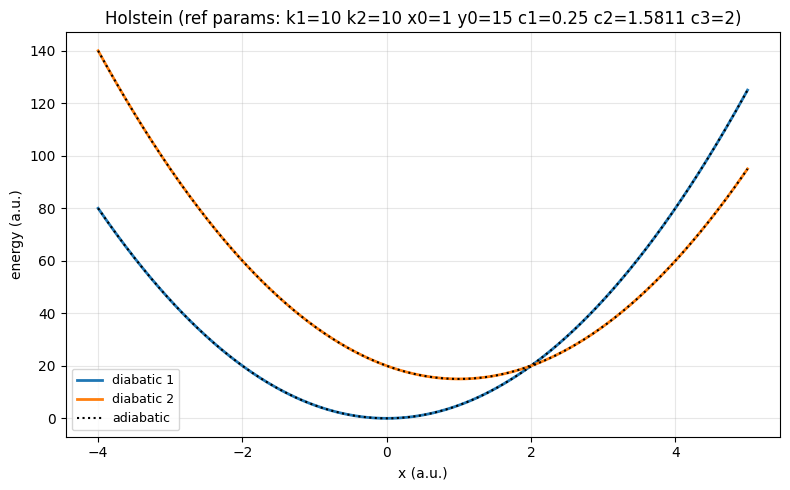

In [8]:
if case == 0:
    model = mdl.build_model(model_params)
    print(model["name"])
    plot.plot_potentials(model, xlim=(-10, 10))

elif case == 1:
    model = mdl.build_model(model_params)
    print("%s   (N=%d, D=%d)" % (model["name"], model["N"], model["D"]))
    # a 1D cut along one nuclear coordinate is not very informative here: each
    # site's diagonal potential depends only on its OWN bath modes, so two of
    # the three diabatic states are exactly flat along any single coordinate.
    # mode=0 (site 1's lowest-frequency mode) is nearly flat too -- mode=19
    # (site 1's highest-frequency mode) shows visible curvature instead.
    plot.plot_potentials(model, mode=0, xlim=(-10, 10))
    nmodes_per_site = model_params["kwargs"].get("nmodes_per_site", 20)
    plot.plot_potentials(model, mode=nmodes_per_site - 1, xlim=(-3, 3))
    # the more natural view for a multi-site exciton model: site energies +
    # the (x-independent) electronic coupling matrix J.
    plot.plot_couplings(model, names=["site %d" % (i + 1) for i in range(model["N"])],
                        title=model["name"])

elif case in [2, 21]:
    model = mdl.build_model(model_params)
    print(model["name"])
    xlim = (-45, 5) if case == 2 else (-5, 5)
    plot.plot_potentials(model, xlim=xlim)
    plot.plot_couplings(model, names=["state 1", "state 2"], title=model["name"])

elif case == 3:
    model = mdl.build_model(model_params)
    print(model["name"])
    plot.plot_potentials(model, xlim=(-4, 5))

elif case == 4:
    # one reference model (c1 = first scan value) just to show the surface shape;
    # the scan itself builds a fresh model per c1 in the run step below
    model = mdl.build_model(dict(model=model_params["model"],
                             kwargs=dict(model_params["kwargs"],
                                        c1=model_params["c1_values"][0])))
    print(model["name"])
    plot.plot_potentials(model, xlim=(-4, 5))

elif case == 5:
    model = mdl.build_model(model_params)
    print(model["name"])
    kw = model_params["kwargs"]
    xlo = min(kw["X1"], kw["X2"], kw["X3"]) - 3
    xhi = max(kw["X1"], kw["X2"], kw["X3"]) + 3
    # 1-D cuts through the coupling centre (X3, 0) -- along X, H12 vanishes
    # everywhere (it's proportional to Y=0); along Y, it's the cut that
    # actually shows the coupling turning on away from the seam.
    plot.plot_potentials(model, mode=0, other=[kw["X3"], 0.0], xlim=(xlo, xhi))
    plot.plot_potentials(model, mode=1, other=[kw["X3"], 0.0], xlim=(-3, 3))
    # the real picture: a 2-D view showing the two adiabatic sheets and the
    # adiabatic gap E2-E1 pinching to EXACTLY zero at the conical intersection
    # (X3, 0) -- the diagnostic that distinguishes a true crossing from a
    # merely-close avoided one.
    plot.plot_surface_2d(model, xlim=(xlo, xhi), ylim=(-3, 3),
                         which="adiabatic", title=model["name"])
    plot.plot_surface_2d(model, xlim=(xlo, xhi), ylim=(-3, 3),
                         which="diabatic", title=model["name"])

elif case == 6:
    model = mdl.build_model(model_params)
    print(model["name"])
    plot.plot_potentials(model, xlim=(-10, 10))

elif case == 7:
    model = mdl.build_model(model_params)
    print(model["name"])
    # wide range: V12 doesn't vanish at large +x (saturates to 2B), so the
    # "extended coupling region" is genuinely visible across a broad window,
    # not just localised near x=0 like SAC/DAC.
    plot.plot_potentials(model, xlim=(-20, 20))

elif case == 8:
    model = mdl.build_model(model_params)
    print(model["name"])
    fig = plot.plot_potentials(model, xlim=(1.5, 12))
    fig.axes[0].set_ylim(-0.002, 0.05)       # the paper's energy window
    # couplings V_ij(x) on their own axis (they are ~100x smaller)
    xs = np.linspace(1.5, 12, 600)
    Vx = compute.potential_matrix(model, xs[:, None])
    plt.figure(figsize=(8, 2.8))
    for (i, j) in [(0, 1), (0, 2), (1, 2)]:
        if np.any(Vx[:, i, j] != 0):
            plt.plot(xs, Vx[:, i, j], lw=2, label="V%d%d" % (i + 1, j + 1))
    plt.xlabel("x (a.u.)"); plt.ylabel("coupling (a.u.)"); plt.legend()
    plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

elif case == 10:
    model = mdl.build_model(model_params)
    print(model["name"])
    print("harmonic fits (k, Re_eff, offset):\n%s" % np.round(model["harmonic"], 5))
    fig = plot.plot_potentials(model, xlim=(1.5, 12))
    fig.axes[0].set_ylim(-0.002, 0.05)
    xs = np.linspace(1.5, 12, 600)
    Vx = compute.potential_matrix(model, xs[:, None])
    plt.figure(figsize=(8, 2.8))
    for (i, j) in [(0, 1), (0, 2), (1, 2)]:
        if np.any(Vx[:, i, j] != 0):
            plt.plot(xs, Vx[:, i, j], lw=2, label="V%d%d" % (i + 1, j + 1))
    plt.xlabel("x (a.u.)"); plt.ylabel("coupling (a.u.)"); plt.legend()
    plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

elif case == 9:
    model = mdl.build_model(model_params)
    print(model["name"])
    # R3 (the coupling centre) and R0 (where the packet starts) come from the
    # variant: R3 from the model's gauss term, R0 from villaseco_init.
    variant = model_params["kwargs"].get("variant", 1)
    R0, c0 = initialize.villaseco_init(model, variant)
    R3 = float(np.asarray(model["gauss"]["xc"], float)[0])
    print("variant %d: starts on diabat %d at R0 = %.2f, coupling centred at R3 = %.3f"
          % (variant, int(np.argmax(c0)) + 1, R0, R3))
    lo, hi = min(R0, R3) - 3.0, max(R0, R3, 8.0) + 1.0
    fig = plot.plot_potentials(model, xlim=(lo, hi))
    fig.axes[0].set_ylim(-0.005, 0.5 if model["E"][1] > 0.1 else 0.12)
    xs = np.linspace(lo, hi, 600)
    Vx = compute.potential_matrix(model, xs[:, None])
    plt.figure(figsize=(8, 2.8))
    plt.plot(xs, Vx[:, 0, 1], lw=2, label="V12")
    plt.axvline(R3, color="k", ls=":", lw=1, label="R3 (coupling centre)")
    plt.axvline(R0, color="g", ls="--", lw=1, label="R0 (start)")
    plt.xlabel("R (bohr)"); plt.ylabel("coupling (a.u.)"); plt.legend()
    plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

else:
    raise ValueError(f"Unsupported case: {case}")

## 2. Run the dynamics

In [9]:
# Helpers live in examples/model.py: mdl.exact_steps, mdl.run_case,
# mdl.write_observables.  Every case writes to mdl.outdir_for(case).

if case == 0:
    res = mdl.run_case(case, model, dyn_params)
    print("final diabatic populations: %s" % np.round(res["pops"][-1], 4))
    print("conservation: dE=%.1e  dN=%.1e" % (res["dEmax"], res["dNmax"]))

    # exact split-operator reference from the SAME psi_1(x,0), psi_2(x,0).
    # The window holds both branches up to t_max; converged: dt_exact 0.1,
    # 0.05 and 0.02 and a doubled grid give the same final populations.
    MASS = float(model["mass"][0])
    Cc, Dc = model_params["kwargs"]["C"], model_params["kwargs"]["D"]
    x, k, dx = compute.grid(-20.0, 25.0, 4096)
    v1, v2 = model["vfun"][0](0, x), model["vfun"][1](0, x)
    vc = Cc * np.exp(-Dc * x ** 2)
    dt_exact, nsteps_exact = mdl.exact_steps(dyn_params["t_max"], 0.05)
    psi1, psi2 = compute.reconstruct(res, 0, x)
    ex = compute.propagate_exact(psi1, psi2, x, k, MASS, v1, v2, vc,
                                  dt_exact, nsteps_exact, record_every=400)
    P = np.array([np.interp(ex["t"], res["t"], res["pops"][:, i]) for i in (0, 1)]).T
    print("final populations:  exact %s   VGWP %s   max|dP| %.4f"
          % (np.round(ex["pops"][-1], 4), np.round(res["pops"][-1], 4),
             np.max(np.abs(P - ex["pops"]))))

    outdir = mdl.outdir_for(case)
    paths = mdl.write_observables(res, outdir)
    paths.append(mdl.write_table(os.path.join(outdir, "exact.txt"),
                                 ["t", "|c1|^2_exact", "|c2|^2_exact",
                                  "norm_exact", "<x>_1", "<x>_2"],
                                 [ex["t"], ex["pops"][:, 0], ex["pops"][:, 1],
                                  ex["norm"], ex["xmean"][:, 0], ex["xmean"][:, 1]],
                                 title="exact split-operator reference (4096 grid points)"))
    print("wrote %d files to %s/" % (len(paths), outdir))

elif case == 1:
    run_params = dict(dyn_params)
    ntraj, T_K = run_params.pop("ntraj"), run_params.pop("T_K")
    for key in ("q0", "p0", "dt"):    # set per-trajectory below
        run_params.pop(key)
    dt = initialize.suggest_dt(model)

    acc = None
    for it in range(ntraj):
        rng = np.random.default_rng(100 + it)
        q0, p0 = initialize.boltzmann_sample(model, initialize.KB * T_K, rng=rng)
        r = mdl.run_case(case, model, run_params, q0=q0, p0=p0, dt=dt)
        acc = r["pops"] if acc is None else acc + r["pops"]
    last_traj = dict(r, pops=r["pops"].copy())   # one self-consistent trajectory, for densities
    r["pops"] = acc / ntraj
    res = r
    print("%d trajectories, %g K; final site populations: %s"
          % (ntraj, T_K, np.round(res["pops"][-1], 4)))
    # exactly 0 for frozen widths (and for thawed + width_shape="diagonal");
    # nonzero for thawed + "full", where the coupling bracket tilts the packets
    print("last trajectory, max |Z_kl|, k != l: %.3e" % r["offdiag"].max())
    # last_traj is one self-consistent trajectory (q/p/widths belong together);
    # res["pops"] is the ensemble average, which belongs to no single set of
    # Gaussians, so it goes to its own file rather than into observables.txt.
    outdir = mdl.outdir_for(case)
    paths = mdl.write_observables(
        last_traj, outdir,
        note="q/p/widths and |c_i|^2 here are ONE trajectory (the last of %d); "
             "the ensemble average is in ensemble_pops.txt" % ntraj)
    names = ["t"] + ["<|c%d|^2>" % (i + 1) for i in range(model["N"])]
    cols = [res["t"]] + [res["pops"][:, i] for i in range(model["N"])]
    paths.append(mdl.write_table(os.path.join(outdir, "ensemble_pops.txt"),
                                 names, cols,
                                 title="%d-trajectory average at %g K" % (ntraj, T_K)))
    print("wrote %d files to %s/" % (len(paths), outdir))

elif case in [2, 21]:
    run_params = {k: v for k, v in dyn_params.items() if k != "width_mode"}
    frozen = mdl.run_case(case, model, run_params, width_mode="frozen")
    thawed = mdl.run_case(case, model, run_params, width_mode="thawed")
    print("%s : max |pop_frozen - pop_thawed| = %.3e"
          % (model["name"], np.max(np.abs(frozen["pops"] - thawed["pops"]))))
    print("final |c2|^2:  frozen %.4f   thawed %.4f"
          % (frozen["pops"][-1, 1], thawed["pops"][-1, 1]))
    outdir = mdl.outdir_for(case)
    for tag, r in (("frozen", frozen), ("thawed", thawed)):
        paths = mdl.write_observables(r, os.path.join(outdir, tag))
        print("wrote %d files to %s/%s/" % (len(paths), outdir, tag))

elif case == 3:
    K1, MASS = model_params["kwargs"]["k1"], model_params["kwargs"]["mass"]
    K2, X0, Y0 = model_params["kwargs"]["k2"], model_params["kwargs"]["x0"], model_params["kwargs"]["y0"]
    C1, C2, C3 = model_params["kwargs"]["c1"], model_params["kwargs"]["c2"], model_params["kwargs"]["c3"]

    # exact-grid reference covers the SAME t_max as the VGWP run below (so the
    # comparison stays meaningful even if DT/NSTEPS changed dyn_params["t_max"]);
    # dt_exact=0.0005 is a fixed, independently-fine split-operator step, capped
    # by mdl.exact_steps() so a very large t_max can't blow up the grid propagation.
    dt_exact, nsteps_exact = mdl.exact_steps(dyn_params["t_max"], 0.0005)
    x, k, dx = compute.grid(-8.0, 8.0, 2048)
    v1 = 0.5 * K1 * x ** 2
    v2 = 0.5 * K2 * (x - X0) ** 2 + Y0
    vc = C1 * np.exp(-C2 * (x - C3) ** 2)
    # VGWP first: the exact TDSE then starts from the SAME psi_1(x,0) and
    # psi_2(x,0) as the VGWP run -- including the seeded psi_2 (seed_mode) --
    # so the comparison is like-for-like.
    res = mdl.run_case(case, model, dyn_params)
    psi1, psi2 = compute.reconstruct(res, 0, x)
    ex = compute.propagate_exact(psi1, psi2, x, k, MASS, v1, v2, vc,
                                  dt_exact, nsteps_exact, record_every=100)
    print("exact (2048 grid pts, t_max=%.1f, seed_mode=%r): norm drift %.2e"
          % (dyn_params["t_max"], res["seed_mode"], np.max(np.abs(ex["norm"] - 1.0))))
    P = np.array([np.interp(ex["t"], res["t"], res["pops"][:, i]) for i in (0, 1)]).T
    print("final |c2|^2:  exact %.4f   VGWP %.4f   max|dP| %.4f"
          % (ex["pops"][-1, 1], res["pops"][-1, 1], np.max(np.abs(P - ex["pops"]))))

    outdir = mdl.outdir_for(case)
    paths = mdl.write_observables(res, outdir)
    paths.append(mdl.write_table(os.path.join(outdir, "exact.txt"),
                                 ["t", "|c1|^2_exact", "|c2|^2_exact",
                                  "norm_exact", "<x>_1", "<x>_2"],
                                 [ex["t"], ex["pops"][:, 0], ex["pops"][:, 1],
                                  ex["norm"], ex["xmean"][:, 0], ex["xmean"][:, 1]],
                                 title="exact split-operator reference (2048 grid points)"))
    print("wrote %d files to %s/" % (len(paths), outdir))

elif case == 4:
    K1, MASS = model_params["kwargs"]["k1"], model_params["kwargs"]["mass"]
    K2, X0, Y0 = model_params["kwargs"]["k2"], model_params["kwargs"]["x0"], model_params["kwargs"]["y0"]
    C2, C3 = model_params["kwargs"]["c2"], model_params["kwargs"]["c3"]
    q0 = dyn_params["q0"]
    run_params = {k: v for k, v in dyn_params.items() if k != "q0"}

    # same reasoning as case 3: track dyn_params["t_max"] rather than a fixed window
    dt_exact0, nsteps_exact = mdl.exact_steps(run_params["t_max"], 0.001)

    curves = {}
    print(" %-6s %-12s %-12s %-12s" % ("c1", "max|dP|", "|c2|^2 exact", "VGWP"))
    for c1 in model_params["c1_values"]:
        x, k, _ = compute.grid(-8.0, 8.0, 2048)
        v1 = 0.5 * K1 * x ** 2
        v2 = 0.5 * K2 * (x - X0) ** 2 + Y0
        vc = c1 * np.exp(-C2 * (x - C3) ** 2)
        psi1 = compute.gaussian_on_grid(x, run_params.get("width_scale", 1.0) * run_params["Z0"].real, q0, 0.0)
        ex = compute.propagate_exact(psi1, np.zeros_like(psi1), x, k, MASS, v1, v2, vc,
                                      dt_exact0, nsteps_exact, record_every=100)

        m = mdl.build_model(dict(model=model_params["model"],
                             kwargs=dict(model_params["kwargs"], c1=c1)))
        r = mdl.run_case(case, m, run_params, q0=[[q0], [q0]])
        P = np.array([np.interp(ex["t"], r["t"], r["pops"][:, i]) for i in (0, 1)]).T
        err = np.max(np.abs(P - ex["pops"]))
        curves[c1] = (ex, r)
        print(" %-6.2f %-12.4f %-12.4f %-12.4f"
              % (c1, err, ex["pops"][-1, 1], r["pops"][-1, 1]))
        sub = os.path.join(mdl.outdir_for(case), "c1_%.2f" % c1)
        mdl.write_observables(r, sub)
        mdl.write_table(os.path.join(sub, "exact.txt"),
                        ["t", "|c1|^2_exact", "|c2|^2_exact", "norm_exact"],
                        [ex["t"], ex["pops"][:, 0], ex["pops"][:, 1], ex["norm"]],
                        title="exact split-operator reference, c1=%.2f" % c1)
    print("wrote per-c1 output under %s/" % mdl.outdir_for(case))

elif case == 5:
    # D=2 and thawed: the one case where the width matrix actually tilts.
    res = mdl.run_case(case, model, dyn_params)
    print("width_shape=%r, width_mode=%r" % (res["width_shape"], res["width_mode"]))
    print("final populations: %s" % np.round(res["pops"][-1], 4))
    print("conservation: dE=%.1e  dN=%.1e" % (res["dEmax"], res["dNmax"]))
    imax = np.argmax(res["pops"][:, 1])
    print("max population transferred to state 1: %.4f at t=%.0f"
          % (res["pops"][:, 1].max(), res["t"][imax]))
    # the diagnostic for whether the full matrix was worth it: 0 would mean the
    # packets never tilted and the diagonal ansatz would have been exact here.
    zmax = 0.0
    for i in range(res["N"]):
        for k in range(res["D"]):
            zkk = np.abs(res["Z"][:, i, k, k]).max()
            if zkk > zmax:
                zmax = float(zkk)
    print("max |Z_kl|, k != l:  %.4f   (max |Z_kk| = %.4f)"
          % (res["offdiag"].max(), zmax))
    # exact SOFT reference: split-operator Fourier propagation of the 2-state
    # TDSE on an (X, Y) grid, from the SAME psi_1, psi_2 at t=0 as the VGWP run.
    # Converged: 256 x 128 points, dt_exact=0.25 (doubling either grid
    # direction, widening it, or halving dt changes the final P2 < 1e-5).
    axes = [np.linspace(-1.0, 8.0, 256, endpoint=False),
            np.linspace(-2.5, 2.5, 128, endpoint=False)]
    XY = np.stack(np.meshgrid(*axes, indexing="ij"), -1).reshape(-1, 2)
    psi0 = np.array([g.reshape(len(axes[0]), len(axes[1]))
                     for g in compute.reconstruct(res, 0, XY)])
    dt_exact = 0.25
    ex = compute.propagate_exact_grid(model, psi0, axes, dt_exact,
                                      int(round(dyn_params["t_max"] / dt_exact)),
                                      record_every=max(1, int(round((res["t"][1] - res["t"][0]) / dt_exact))))
    P = np.array([np.interp(ex["t"], res["t"], res["pops"][:, i]) for i in (0, 1)]).T
    print("exact SOFT (256 x 128 grid): final populations %s   VGWP %s   max|dP| %.4f"
          % (np.round(ex["pops"][-1], 4), np.round(res["pops"][-1], 4),
             np.max(np.abs(P - ex["pops"]))))

    outdir = mdl.outdir_for(case)
    paths = mdl.write_observables(res, outdir)
    paths.append(mdl.write_table(os.path.join(outdir, "exact.txt"),
                                 ["t", "|c1|^2_exact", "|c2|^2_exact",
                                  "<X>_1", "<Y>_1", "<X>_2", "<Y>_2"],
                                 [ex["t"], ex["pops"][:, 0], ex["pops"][:, 1],
                                  ex["xmean"][:, 0, 0], ex["xmean"][:, 0, 1],
                                  ex["xmean"][:, 1, 0], ex["xmean"][:, 1, 1]],
                                 title="exact SOFT reference (256 x 128 (X, Y) grid, dt=0.25)"))
    print("wrote %d files to %s/" % (len(paths), outdir))

elif case == 6:
    res = mdl.run_case(case, model, dyn_params)
    print("final diabatic populations: %s" % np.round(res["pops"][-1], 4))
    print("conservation: dE=%.1e  dN=%.1e" % (res["dEmax"], res["dNmax"]))
    paths = mdl.write_observables(res, mdl.outdir_for(case))
    print("wrote %d files to %s/" % (len(paths), mdl.outdir_for(case)))

elif case == 7:
    print("dt=%.4f (see the extra safety-margin note in dyn_params above)" % dyn_params["dt"])
    res = mdl.run_case(case, model, dyn_params)
    print("final populations: %s" % np.round(res["pops"][-1], 4))
    print("conservation: dE=%.1e  dN=%.1e" % (res["dEmax"], res["dNmax"]))
    paths = mdl.write_observables(res, mdl.outdir_for(case))
    print("wrote %d files to %s/" % (len(paths), mdl.outdir_for(case)))

elif case == 8:
    # VGWP, then the exact SOFT reference: split-operator propagation of the
    # 3-state TDSE on a grid, from the SAME psi_1, psi_2, psi_3 at t=0.
    # Converged: x in [0.5, 30) with 4096 points, dt_exact = 0.5 (a coarser
    # grid or larger dt gives the same populations; nothing reaches the edge).
    res = mdl.run_case(case, model, dyn_params)
    print("VGWP final populations: %s   dE %.1e  dN %.1e"
          % (np.round(res["pops"][-1], 4), res["dEmax"], res["dNmax"]))
    axes = [np.linspace(0.5, 30.0, 4096, endpoint=False)]
    psi0 = np.array(compute.reconstruct(res, 0, axes[0][:, None]))
    dt_exact = 0.5
    ex = compute.propagate_exact_grid(model, psi0, axes, dt_exact,
                                      int(round(dyn_params["t_max"] / dt_exact)),
                                      record_every=max(1, int(round((res["t"][1] - res["t"][0]) / dt_exact))))
    P = np.array([np.interp(ex["t"], res["t"], res["pops"][:, i])
                  for i in range(model["N"])]).T
    print("exact SOFT final populations: %s   max|dP| %.4f"
          % (np.round(ex["pops"][-1], 4), np.max(np.abs(P - ex["pops"]))))

    outdir = mdl.outdir_for(case)
    paths = mdl.write_observables(res, outdir)
    names = ["t"] + ["|c%d|^2_exact" % (i + 1) for i in range(model["N"])] + \
            ["<x>_%d" % (i + 1) for i in range(model["N"])]
    cols = [ex["t"]] + [ex["pops"][:, i] for i in range(model["N"])] + \
           [ex["xmean"][:, i, 0] for i in range(model["N"])]
    paths.append(mdl.write_table(os.path.join(outdir, "exact.txt"), names, cols,
                                 title="exact SOFT reference (4096-point grid, dt=0.5)"))
    print("wrote %d files to %s/" % (len(paths), outdir))

elif case == 10:
    # Same initial condition as case 8 (ground-state packet on state 1 at the
    # ground-state Re), on the approximated surfaces.  No seed tracking is
    # needed here, and the run conserves E and N to ~1e-12 / 1e-10.
    res = mdl.run_case(case, model, dyn_params)
    print("VGWP final populations: %s   dE %.1e  dN %.1e"
          % (np.round(res["pops"][-1], 4), res["dEmax"], res["dNmax"]))
    axes = [np.linspace(0.5, 30.0, 4096, endpoint=False)]
    psi0 = np.array(compute.reconstruct(res, 0, axes[0][:, None]))
    dt_exact = 0.5
    ex = compute.propagate_exact_grid(model, psi0, axes, dt_exact,
                                      int(round(dyn_params["t_max"] / dt_exact)),
                                      record_every=max(1, int(round((res["t"][1] - res["t"][0]) / dt_exact))))
    P = np.array([np.interp(ex["t"], res["t"], res["pops"][:, i])
                  for i in range(model["N"])]).T
    print("exact SOFT final populations: %s   max|dP| %.4f"
          % (np.round(ex["pops"][-1], 4), np.max(np.abs(P - ex["pops"]))))
    paths = mdl.write_observables(res, mdl.outdir_for(case))
    print("wrote %d files to %s/" % (len(paths), mdl.outdir_for(case)))

elif case == 9:
    # All population starts on diabat 1 at the Franck-Condon point R0 = 2.
    # The packet then slides towards that diabat's minimum at R1 = 6, crossing
    # the Gaussian coupling at R3 = 3.875.
    res = mdl.run_case(case, model, dyn_params)
    print("VGWP final populations: %s   dE %.1e  dN %.1e"
          % (np.round(res["pops"][-1], 4), res["dEmax"], res["dNmax"]))
    # exact SOFT reference from the SAME psi_1(R,0), psi_2(R,0)
    axes = [np.linspace(-2.0, 16.0, 4096, endpoint=False)]
    psi0 = np.array(compute.reconstruct(res, 0, axes[0][:, None]))
    dt_exact = 0.5
    ex = compute.propagate_exact_grid(model, psi0, axes, dt_exact,
                                      int(round(dyn_params["t_max"] / dt_exact)),
                                      record_every=max(1, int(round((res["t"][1] - res["t"][0]) / dt_exact))))
    P = np.array([np.interp(ex["t"], res["t"], res["pops"][:, i])
                  for i in range(model["N"])]).T
    print("exact SOFT final populations: %s   max|dP| %.4f"
          % (np.round(ex["pops"][-1], 4), np.max(np.abs(P - ex["pops"]))))
    # NOTE: the two Gaussians never meet at the crossing -- diabat 2's packet
    # sits at its own minimum R2 = 2 while diabat 1's travels through R3 --
    # so <g1|V12|g2> stays ~1e-6 against a coupling of b = 0.01 and VGWP
    # transfers nothing.  The exact solution instead CREATES a second lobe on
    # diabat 2 at the crossing, which one Gaussian per state cannot hold.
    # dyn_params' seed_track note covers what happens if that is switched on.
    paths = mdl.write_observables(res, mdl.outdir_for(case))
    print("wrote %d files to %s/" % (len(paths), mdl.outdir_for(case)))

else:
    raise ValueError(f"Unsupported case: {case}")

 c1     max|dP|      |c2|^2 exact VGWP        
 0.25   0.0016       0.0004       0.0002      
 1.00   0.0317       0.1038       0.0797      
 2.00   0.3472       0.2566       0.6037      
wrote per-c1 output under holstein_scan_output/


## 3. Plot populations

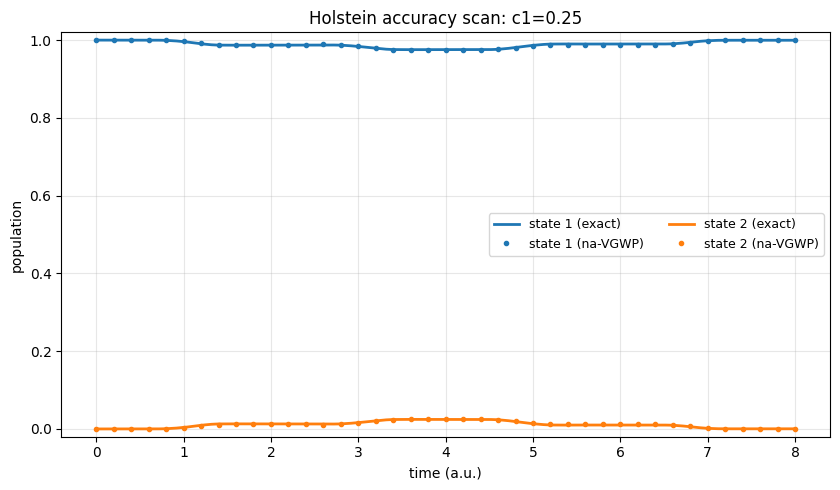

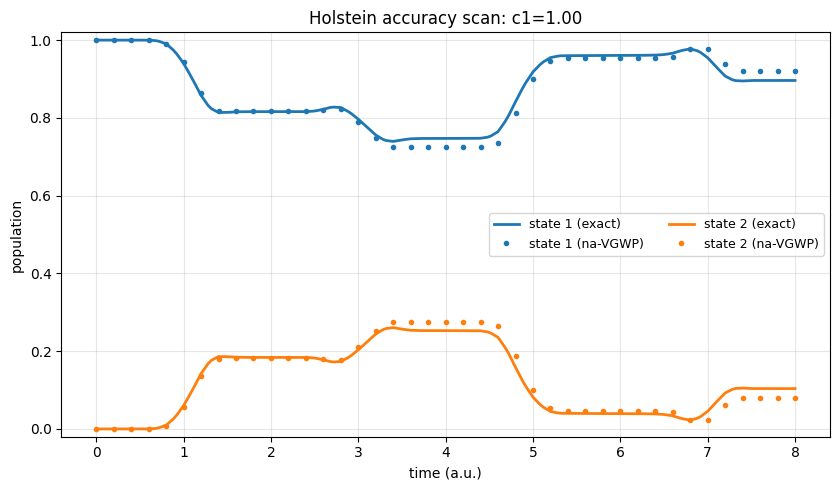

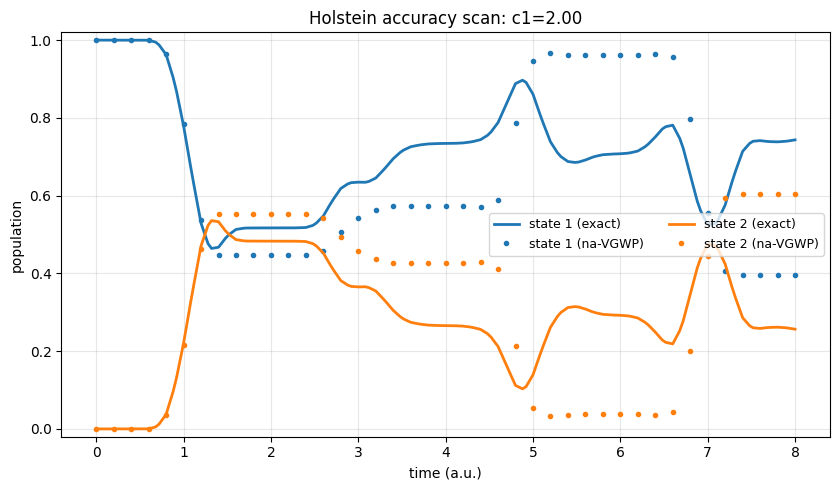

In [10]:
if case == 0:
    exact_on_r = np.array([np.interp(res["t"], ex["t"], ex["pops"][:, i])
                           for i in (0, 1)]).T
    plot.plot_populations(res, exact=exact_on_r, **plot_params)

elif case == 1:
    plot.plot_populations(res, **plot_params)

elif case in [2, 21]:
    plot.plot_populations(frozen, names=["state 1", "state 2"],
                           title=model["name"] + " (frozen)")

elif case == 3:
    pass  # redundant -- the population panel in plot_summary (next cell) already covers it

elif case == 4:
    for c1, (ex, r) in curves.items():
        exact_on_r = np.array([np.interp(r["t"], ex["t"], ex["pops"][:, i])
                               for i in (0, 1)]).T
        plot.plot_populations(r, exact=exact_on_r,
                               title="Holstein accuracy scan: c1=%.2f" % c1,
                               **plot_params)

elif case == 5:
    exact_on_r = np.array([np.interp(res["t"], ex["t"], ex["pops"][:, i])
                           for i in (0, 1)]).T
    plot.plot_populations(res, exact=exact_on_r, **plot_params)

elif case == 6:
    plot.plot_populations(res, **plot_params)

elif case == 7:
    plot.plot_populations(res, **plot_params)

elif case == 8:
    exact_on_r = np.array([np.interp(res["t"], ex["t"], ex["pops"][:, i])
                           for i in range(model["N"])]).T
    plot.plot_populations(res, exact=exact_on_r, t_scale=1.0 / 41.341374575751,
                          t_label="time (fs)", **plot_params)

elif case == 10:
    exact_on_r = np.array([np.interp(res["t"], ex["t"], ex["pops"][:, i])
                           for i in range(model["N"])]).T
    plot.plot_populations(res, exact=exact_on_r, **plot_params)

elif case == 9:
    exact_on_r = np.array([np.interp(res["t"], ex["t"], ex["pops"][:, i])
                           for i in range(model["N"])]).T
    plot.plot_populations(res, exact=exact_on_r, t_scale=initialize.FS,
                          t_label="time (fs)", **plot_params)

else:
    raise ValueError(f"Unsupported case: {case}")

## 4. Plot summary

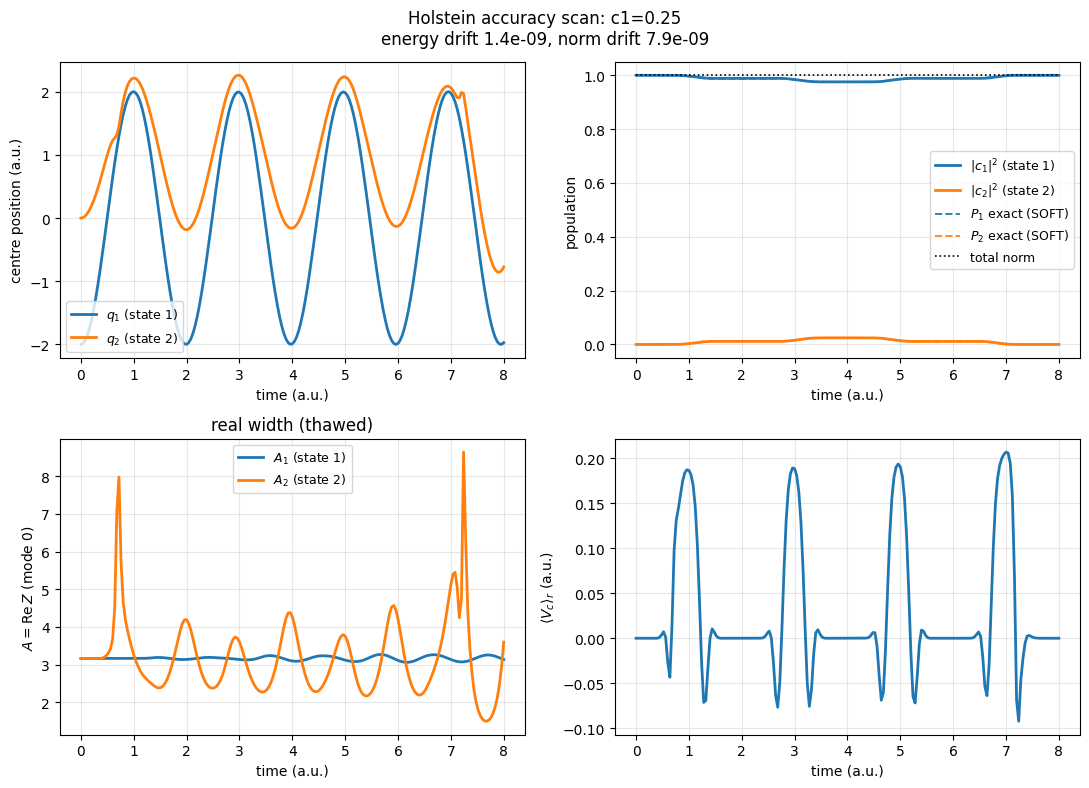

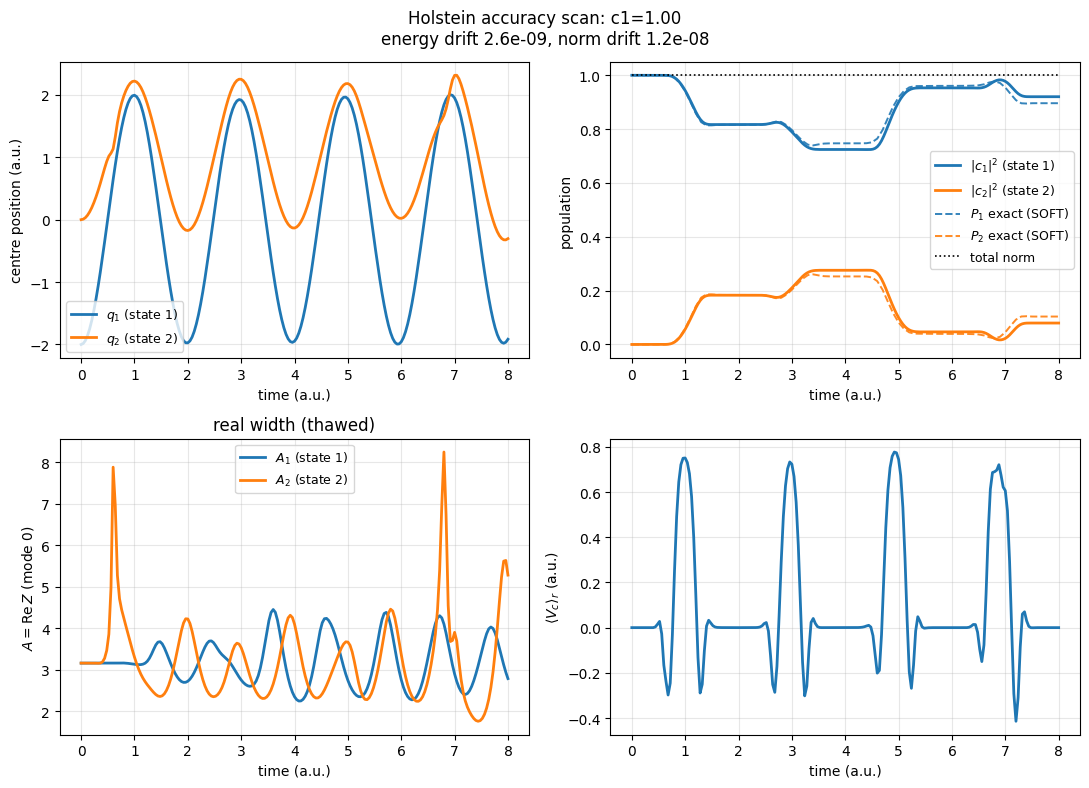

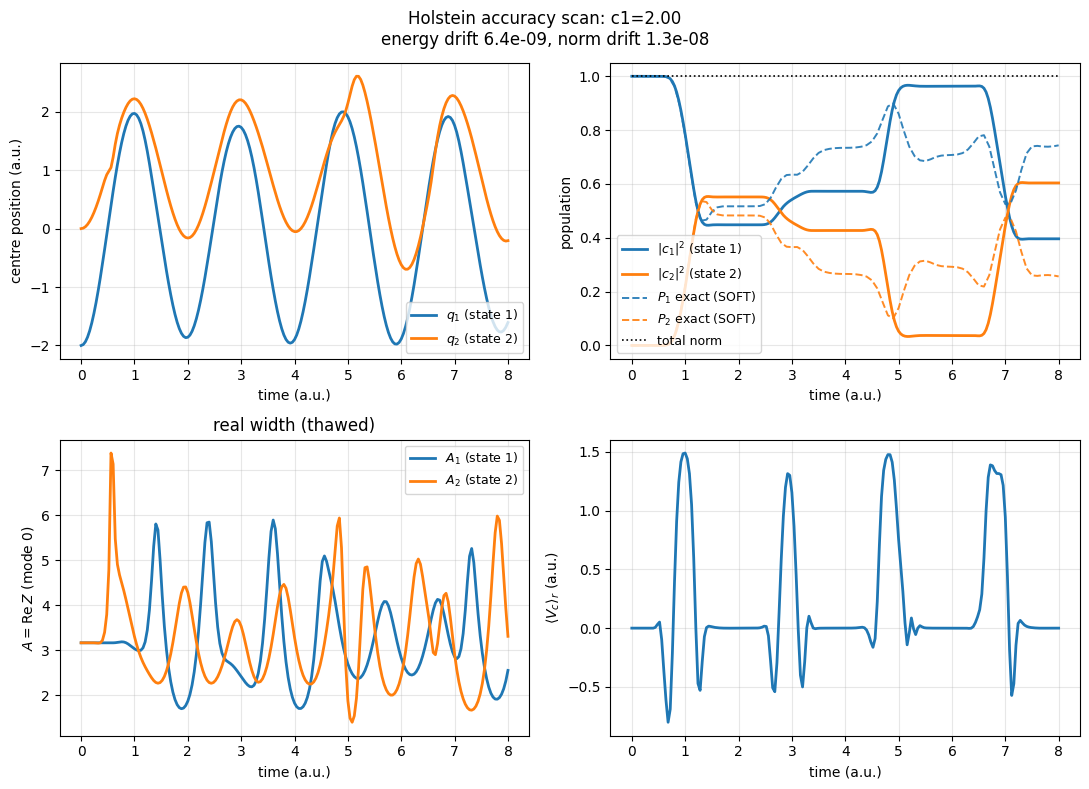

In [11]:
if case == 0:
    plot.plot_summary(res, names=plot_params["names"], title=model["name"], exact=ex)

elif case == 1:
    plot.plot_summary(res, names=plot_params["names"],
                       title=model["name"] + " (last trajectory shown)")

elif case in [2, 21]:
    plot.plot_summary(frozen, names=["state 1", "state 2"],
                       title=model["name"] + " (frozen)")
    plot.plot_summary(thawed, names=["state 1", "state 2"],
                       title=model["name"] + " (thawed)")
    plot.plot_widths([frozen, thawed], labels=["frozen", "thawed"],
                      title=model["name"] + " -- width on state 2", **plot_params)

elif case == 3:
    plot.plot_summary(res, names=plot_params["names"], title=model["name"], exact=ex)

elif case == 4:
    for c1, (ex, r) in curves.items():
        plot.plot_summary(r, names=plot_params["names"],
                           title="Holstein accuracy scan: c1=%.2f" % c1, exact=ex)

elif case == 5:
    plot.plot_summary(res, names=plot_params["names"], title=model["name"], exact=ex)

elif case == 6:
    plot.plot_summary(res, names=plot_params["names"], title=model["name"])

elif case == 7:
    plot.plot_summary(res, names=plot_params["names"], title=model["name"])

elif case == 8:
    plot.plot_summary(res, names=plot_params["names"], title=model["name"], exact=ex)

elif case == 10:
    plot.plot_summary(res, names=plot_params["names"], title=model["name"], exact=ex)

elif case == 9:
    plot.plot_summary(res, names=plot_params["names"], title=model["name"], exact=ex)

else:
    raise ValueError(f"Unsupported case: {case}")

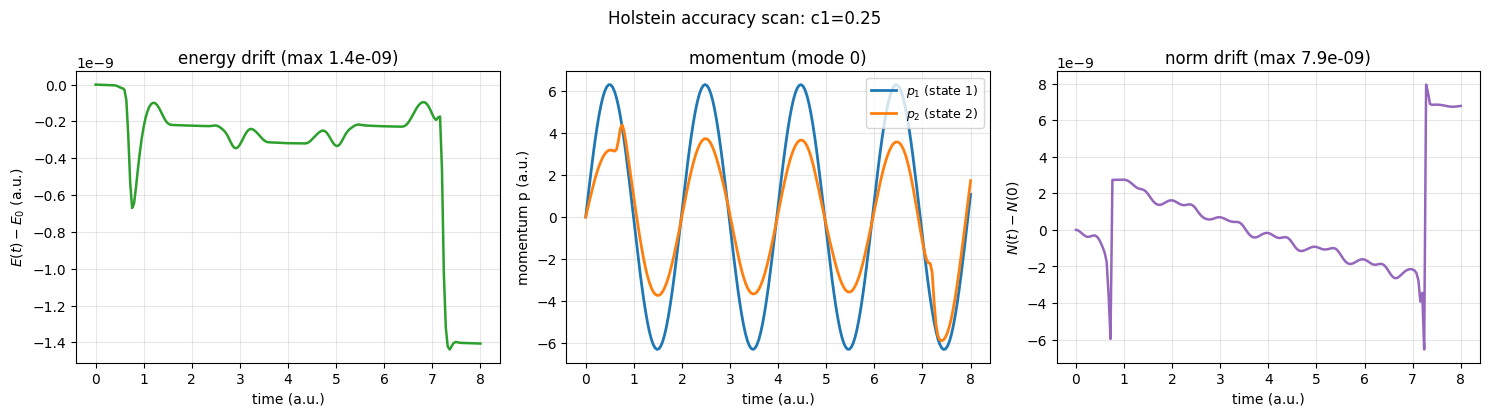

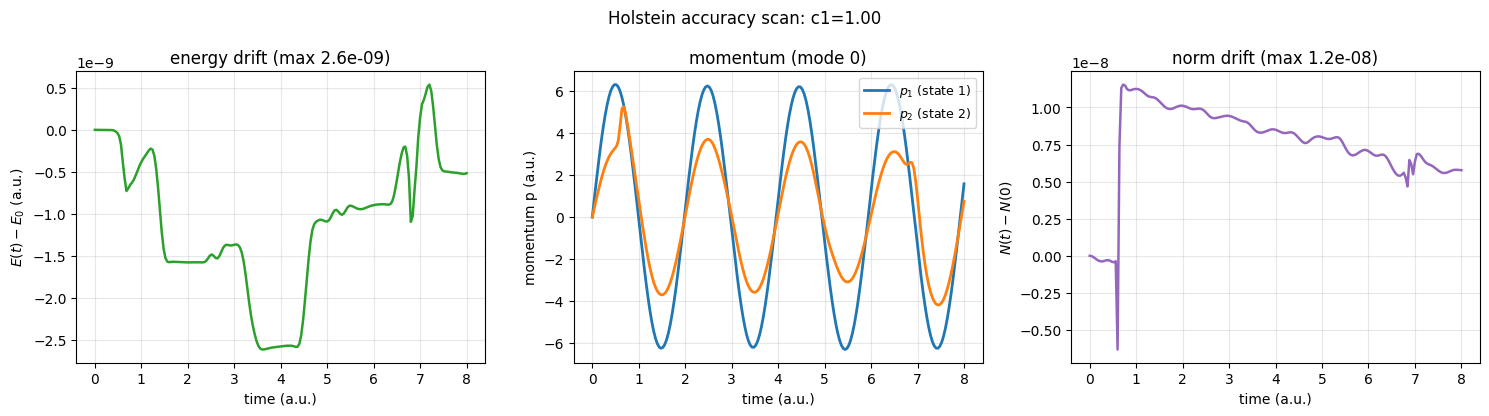

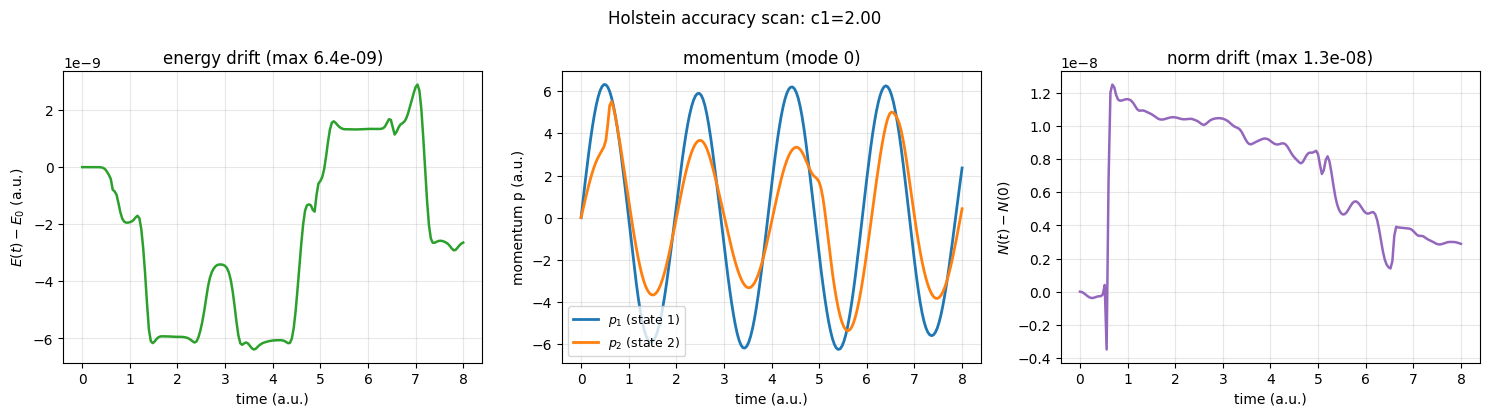

In [12]:
# Energy drift, momentum of every state, and norm drift (not in the summary
# plot above, which shows the width and <V_c> instead).
if case == 1:
    plot.plot_energy_momentum_norm(res, names=plot_params["names"],
                                   title=model["name"] + " (last trajectory shown)")
elif case in [2, 21]:
    plot.plot_energy_momentum_norm(frozen, names=["state 1", "state 2"],
                                   title=model["name"] + " (frozen)")
    plot.plot_energy_momentum_norm(thawed, names=["state 1", "state 2"],
                                   title=model["name"] + " (thawed)")
elif case == 4:
    for c1, (ex, r) in curves.items():
        plot.plot_energy_momentum_norm(r, names=plot_params["names"],
                                       title="Holstein accuracy scan: c1=%.2f" % c1)
else:
    plot.plot_energy_momentum_norm(res, names=plot_params["names"], title=model["name"])
plt.show()

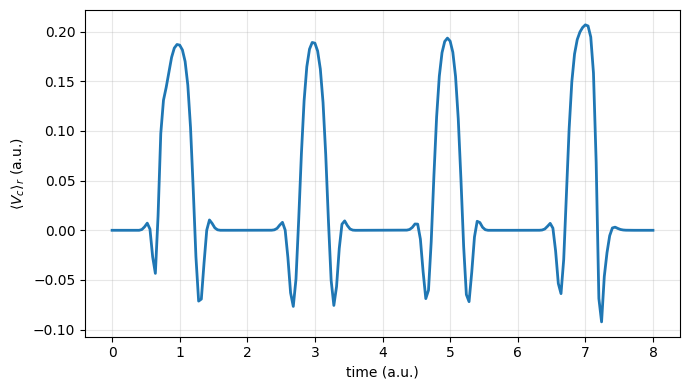

In [13]:
# Coupling matrix element between the Gaussians themselves (no c's), saved by
# the run at every frame:  res["W"][:, i, j] = <g_i|V_ij|g_j>.
# Compare with <V_c> = sum_{i!=j} c_i^* c_j <g_i|V_ij|g_j> in the summary plot.
r = last_traj if case == 1 else (thawed if case in [2, 21] else
                                 (list(curves.values())[0][1] if case == 4 else res))
plot.plot_coupling_element(r)
plt.show()


###### SOFT EQUATIONS OF MOTION AND DYNAMICS
###### Energy for Demonstration
######## Role of Couplings on / Frozen and thawed dynamics
##### How to populate empty states
##### Initialization is crucial for the dynamics, as it sets the initial state of the system.
#### Vertical on SI (State-Independent)


## 5. Plot density snapshots

Per-state density of each nuclear wavepacket at a few times.

For D=1 this is `|psi_i(x)|^2`. For D>1 it is the **reduced density along one
mode** (`"mode"` in `wfc_plt_params`), with every other mode integrated out:
`|c_i|^2 sqrt(a/pi) exp[-a (x-q)^2]`, `a = Re zeta` of that mode. This is exact,
not an approximation, because each Gaussian is a product over modes.

* case 1 (FMO, D=60): the **last trajectory** of the ensemble (densities of
  different trajectories can't be averaged into one Gaussian), one figure
  per site, along that site's bath mode with the largest excited-state
  displacement (in units of the width) -- the mode where the packet visibly
  moves when the exciton is on that site.
* case 4: one figure per coupling strength `c1` in the scan.
* case 5 (Ferretti, D=2): reduced densities along X and Y, plus 2-D contour
  snapshots over the (X, Y) plane with `plot.plot_density_2d`.

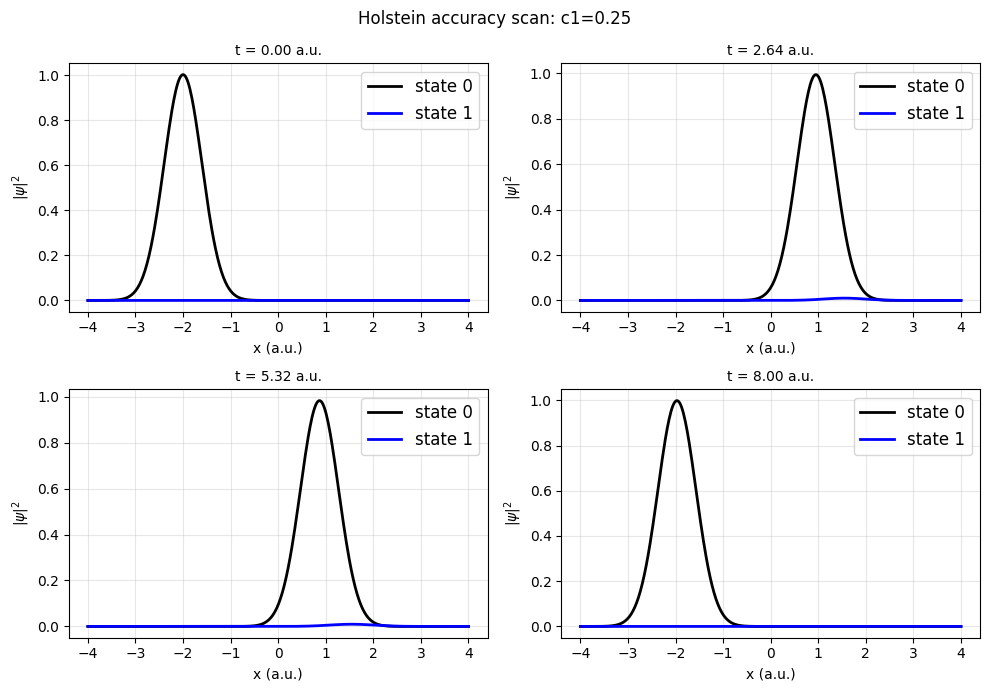

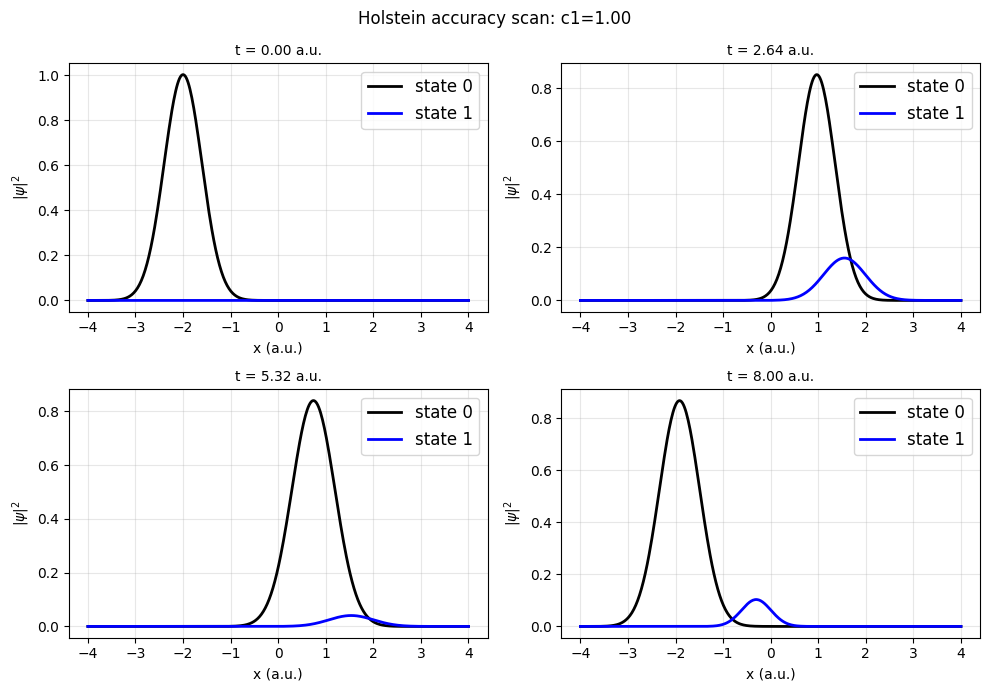

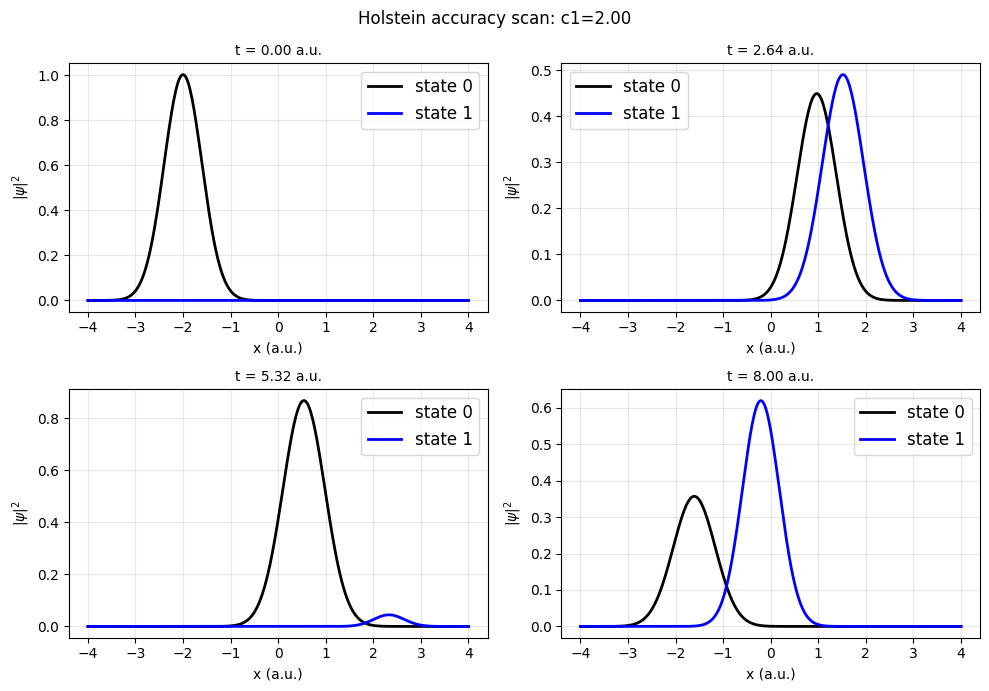

In [14]:
# density_2d, density_axis_range and plot_density_2d_full live in
# examples/model.py.

if case == 0:
    wfc_plt_params = {
        "prefix": model["name"],
        "states": [0, 1], "1Dcolors": ["black", "blue"],
        "size": [10, 7], "legend_loc": "best", "legend_size": 12,
        "xmin": -12.0, "xmax": 10.0, "npoints": 400,
        "snaps": np.linspace(0, len(res["t"]) - 1, 4).astype(int),
    }
    plot.plot_density_grid(res, wfc_plt_params)

elif case == 1:
    # last_traj: one real trajectory (res["pops"] is the ensemble average, which
    # doesn't belong to any single set of Gaussians).  For each site, pick that
    # site's bath mode whose state minimum is displaced furthest in units of
    # the packet width -- the mode where the density visibly shifts.
    a0 = np.real(last_traj["zeta"][0, 0])
    shift = np.abs(model["kappa"] / np.maximum(model["omega2"], 1e-300)) * np.sqrt(a0)
    snaps = np.linspace(0, len(last_traj["t"]) - 1, 4).astype(int)
    for site in range(model["N"]):
        mode = int(np.argmax(shift[site]))
        wfc_plt_params = {
            "prefix": "%s -- last trajectory, mode %d (bath of site %d)"
                      % (model["name"], mode, site + 1),
            "states": list(range(model["N"])),
            "1Dcolors": ["black", "blue", "red"],
            "size": [10, 7], "legend_loc": "best", "legend_size": 10,
            "mode": mode, "npoints": 400, "snaps": snaps,
            "t_scale": initialize.FS, "t_label": "fs",
        }
        plot.plot_density_grid(last_traj, wfc_plt_params)

elif case in [2, 21]:
    xmin, xmax = (-45.0, 5.0) if case == 2 else (-8.0, 8.0)
    wfc_plt_params = {
        "prefix": model["name"] + " (thawed)",
        "states": [0, 1], "1Dcolors": ["black", "blue"],
        "size": [10, 7], "legend_loc": "best", "legend_size": 12,
        "xmin": xmin, "xmax": xmax, "npoints": 400,
        "snaps": np.linspace(0, len(thawed["t"]) - 1, 4).astype(int),
    }
    plot.plot_density_grid(thawed, wfc_plt_params)

elif case == 3:
    wfc_plt_params = {
        "prefix": model["name"],
        "states": [0, 1], "1Dcolors": ["black", "blue"],
        "size": [10, 7], "legend_loc": "best", "legend_size": 12,
        "xmin": -4.0, "xmax": 4.0, "npoints": 400,
        "snaps": np.linspace(0, len(res["t"]) - 1, 4).astype(int),
    }
    plot.plot_density_grid(res, wfc_plt_params)

elif case == 4:
    for c1, (ex, r) in curves.items():
        wfc_plt_params = {
            "prefix": "Holstein accuracy scan: c1=%.2f" % c1,
            "states": [0, 1], "1Dcolors": ["black", "blue"],
            "size": [10, 7], "legend_loc": "best", "legend_size": 12,
            "xmin": -4.0, "xmax": 4.0, "npoints": 400,
            "snaps": np.linspace(0, len(r["t"]) - 1, 4).astype(int),
        }
        plot.plot_density_grid(r, wfc_plt_params)

elif case == 5:
    snaps = np.linspace(0, len(res["t"]) - 1, 4).astype(int)
    for mode, label in [(0, "X (symmetric stretch)"), (1, "Y (antisymmetric stretch)")]:
        wfc_plt_params = {
            "prefix": model["name"] + " -- reduced density along " + label,
            "states": [0, 1], "1Dcolors": ["black", "blue"],
            "size": [10, 7], "legend_loc": "best", "legend_size": 12,
            "mode": mode, "npoints": 400, "snaps": snaps,
        }
        plot.plot_density_grid(res, wfc_plt_params)
    # full width matrix -> the tilt-aware plotter above, not plot.plot_density_2d
    mdl.plot_density_2d_full(res, {"prefix": model["name"] + " -- density over (X, Y)",
                               "states": [0, 1], "snaps": snaps, "modes": [0, 1]})

elif case == 6:
    wfc_plt_params = {
        "prefix": model["name"],
        "states": [0, 1], "1Dcolors": ["black", "blue"],
        "size": [10, 7], "legend_loc": "best", "legend_size": 12,
        "xmin": -17.0, "xmax": 17.0, "npoints": 400,
        "snaps": np.linspace(0, len(res["t"]) - 1, 4).astype(int),
    }
    plot.plot_density_grid(res, wfc_plt_params)

elif case == 7:
    wfc_plt_params = {
        "prefix": model["name"],
        "states": [0, 1], "1Dcolors": ["black", "blue"],
        "size": [10, 7], "legend_loc": "best", "legend_size": 12,
        "xmin": -20.0, "xmax": 25.0, "npoints": 400,
        "snaps": np.linspace(0, len(res["t"]) - 1, 4).astype(int),
    }
    plot.plot_density_grid(res, wfc_plt_params)

elif case == 8:
    wfc_plt_params = {
        "prefix": model["name"],
        "states": [0, 1, 2], "1Dcolors": ["black", "blue", "red"],
        "size": [10, 7], "legend_loc": "best", "legend_size": 12,
        "xmin": 1.5, "xmax": 14.0, "npoints": 400,
        "snaps": np.linspace(0, len(res["t"]) - 1, 4).astype(int),
    }
    plot.plot_density_grid(res, wfc_plt_params)

elif case == 10:
    wfc_plt_params = {
        "prefix": model["name"],
        "states": [0, 1, 2], "1Dcolors": ["black", "blue", "red"],
        "size": [10, 7], "legend_loc": "best", "legend_size": 12,
        "xmin": 1.5, "xmax": 14.0, "npoints": 400,
        "snaps": np.linspace(0, len(res["t"]) - 1, 4).astype(int),
    }
    plot.plot_density_grid(res, wfc_plt_params)

elif case == 9:
    wfc_plt_params = {
        "prefix": model["name"],
        "states": [0, 1], "1Dcolors": ["black", "blue"],
        "size": [10, 7], "legend_loc": "best", "legend_size": 12,
        "xmin": 0.0, "xmax": 9.0, "npoints": 400,
        "snaps": np.linspace(0, len(res["t"]) - 1, 4).astype(int),
    }
    plot.plot_density_grid(res, wfc_plt_params)

else:
    raise ValueError(f"Unsupported case: {case}")

## 6. Plot p, A, z and phase space (p vs q)

For each electronic state, along one nuclear mode (`mode`):

* **q(t)** and **p(t)** -- centre and momentum of the Gaussian,
* **A(t) = Re z** -- the width parameter (larger A = narrower packet; the
  density is `exp[-A (x-q)^2]`, standard deviation `1/sqrt(2A)`),
* **B(t) = Im z** -- the chirp,
* **p vs q** -- the phase-space path of each Gaussian's centre.

`z` is the per-mode width `zeta` (the diagonal of the width matrix Z for an
untilted packet, the marginal width for a tilted one). In the phase-space plot
the line fades where the state is nearly empty, so a seeded state only shows
up once population arrives.

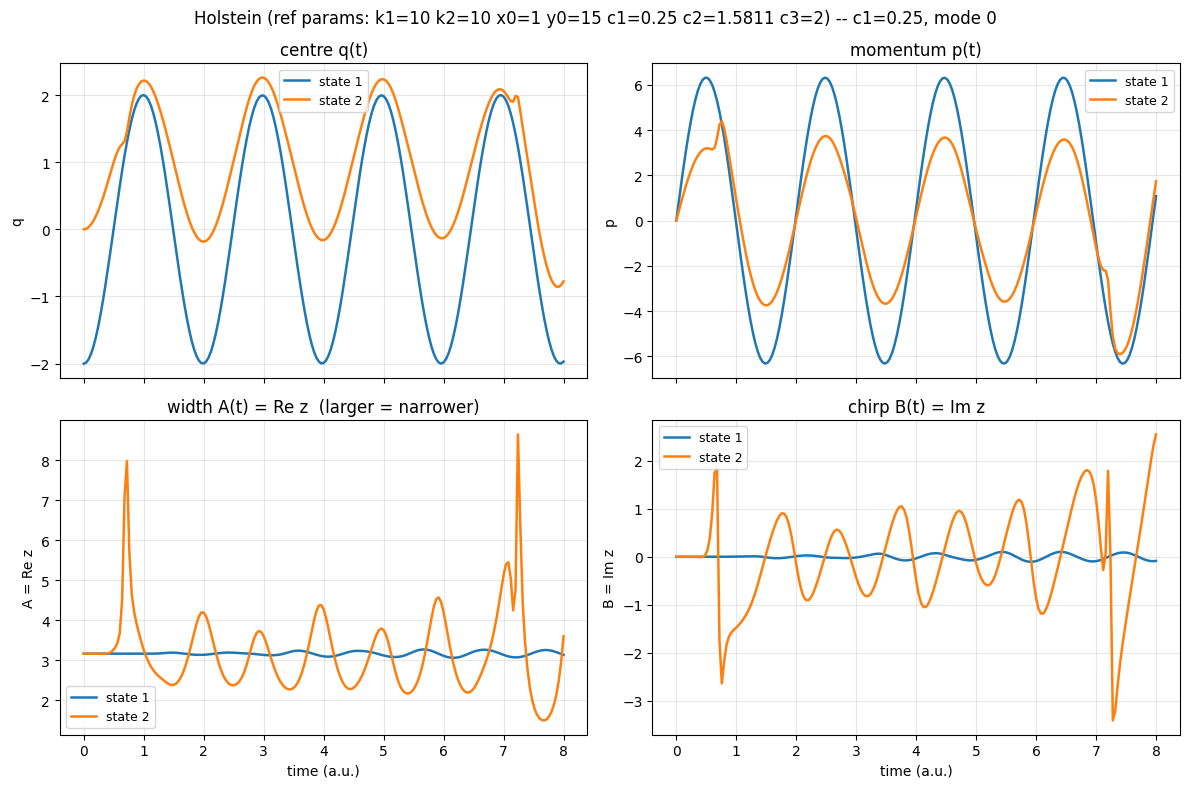

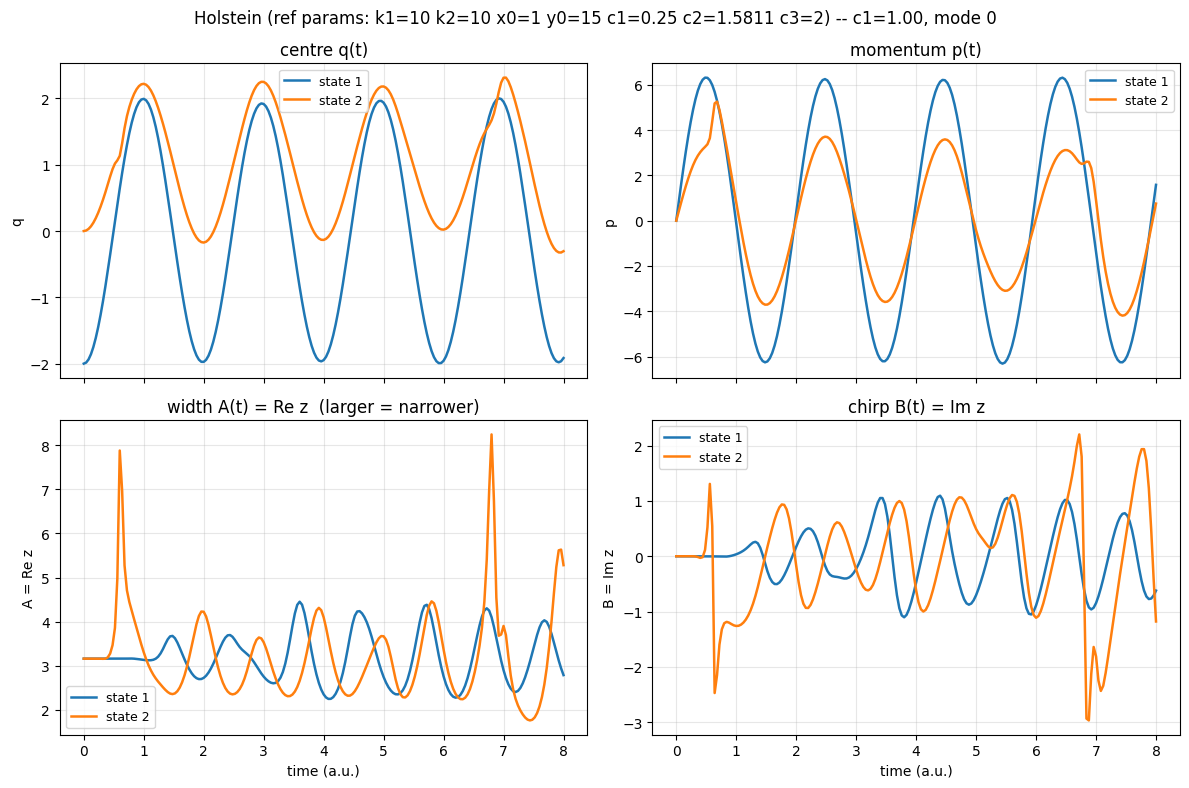

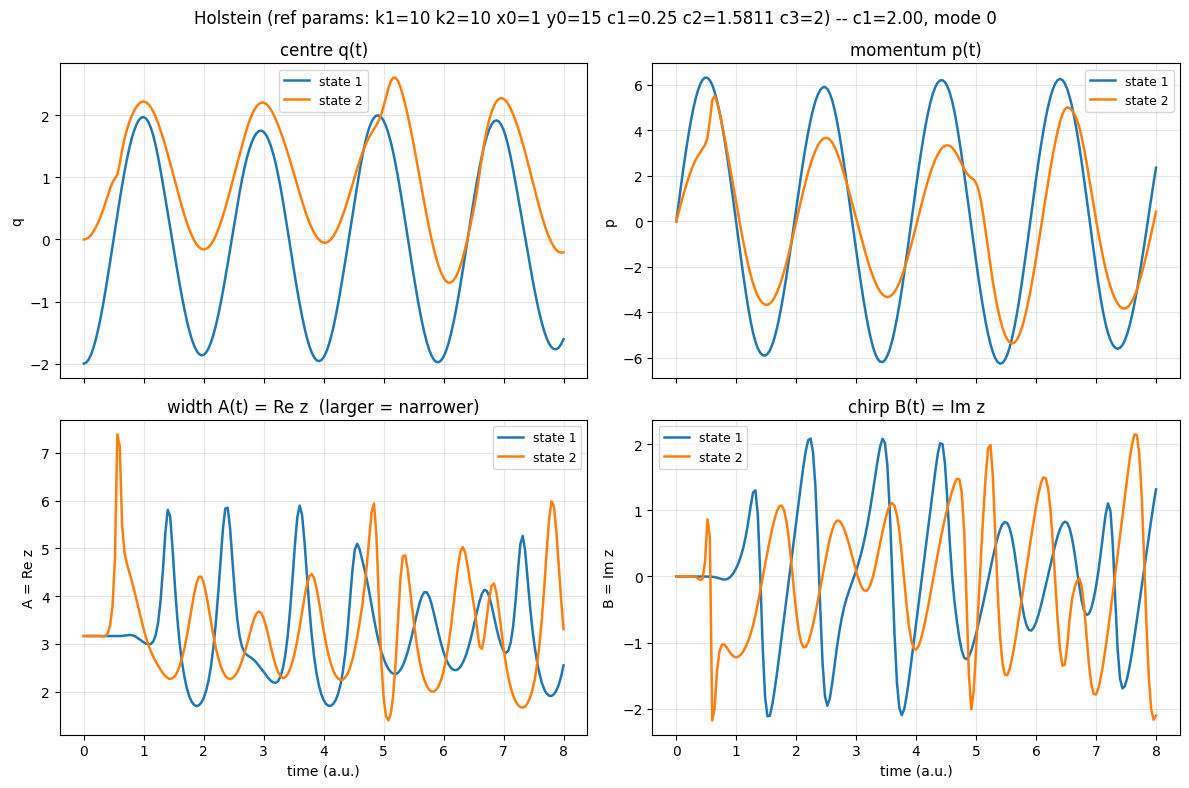

In [15]:
# Plot q, p, A = Re z and B = Im z for every state (phase space: next cell).
# Works for any case: it picks up the result(s) the run cell left in memory.
mode = 0                                    # which nuclear mode to plot

if case in [2, 21]:
    runs = [("frozen", frozen), ("thawed", thawed)]
elif case == 4:
    runs = [("c1=%.2f" % c1, r) for c1, (ex, r) in curves.items()]
elif case == 1:
    runs = [("last trajectory", last_traj)]
else:
    runs = [(res["width_mode"], res)]

for label, r in runs:
    t = r["t"] * (initialize.FS if case == 1 else 1.0)
    t_unit = "fs" if case == 1 else "a.u."
    N = r["N"]
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    pops = np.abs(r["c"]) ** 2 / np.sum(np.abs(r["c"]) ** 2, axis=1)[:, None]

    # ---- q(t), p(t), A(t) = Re z, B(t) = Im z
    fig, ax = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
    for i in range(N):
        kw = dict(color=colors[i % len(colors)], lw=1.8, label="state %d" % (i + 1))
        ax[0, 0].plot(t, r["q"][:, i, mode], **kw)
        ax[0, 1].plot(t, r["p"][:, i, mode], **kw)
        ax[1, 0].plot(t, np.real(r["zeta"][:, i, mode]), **kw)
        ax[1, 1].plot(t, np.imag(r["zeta"][:, i, mode]), **kw)
    for a_, yl, ti in [(ax[0, 0], "q", "centre q(t)"),
                       (ax[0, 1], "p", "momentum p(t)"),
                       (ax[1, 0], "A = Re z", "width A(t) = Re z  (larger = narrower)"),
                       (ax[1, 1], "B = Im z", "chirp B(t) = Im z")]:
        a_.set_ylabel(yl); a_.set_title(ti); a_.grid(alpha=.3); a_.legend(fontsize=9)
    for a_ in ax[1]:
        a_.set_xlabel("time (%s)" % t_unit)
    fig.suptitle("%s -- %s, mode %d" % (model["name"], label, mode))
    fig.tight_layout(); plt.show()

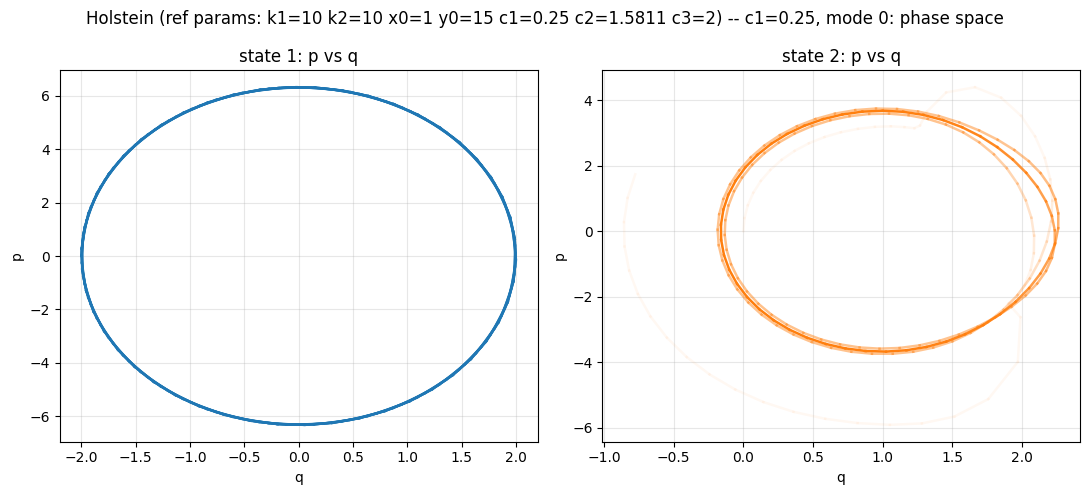

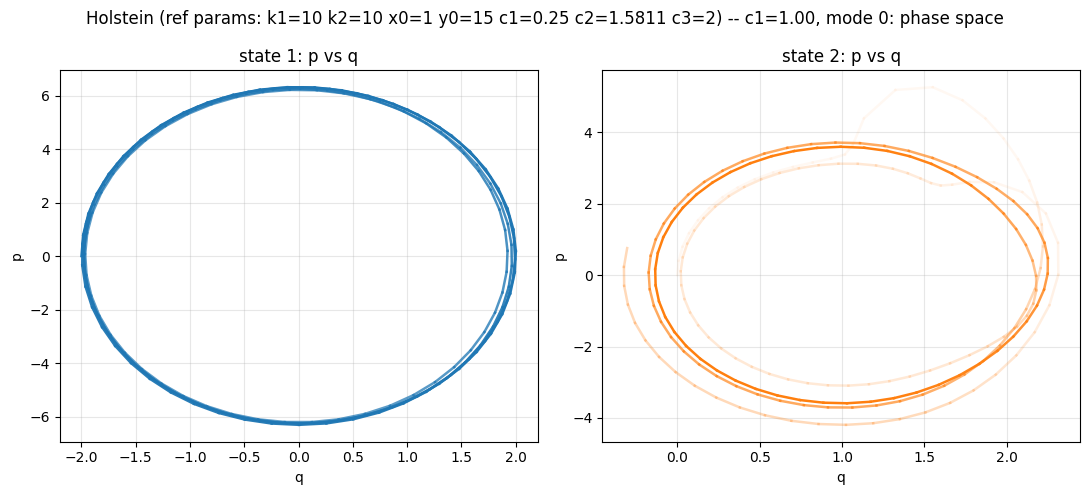

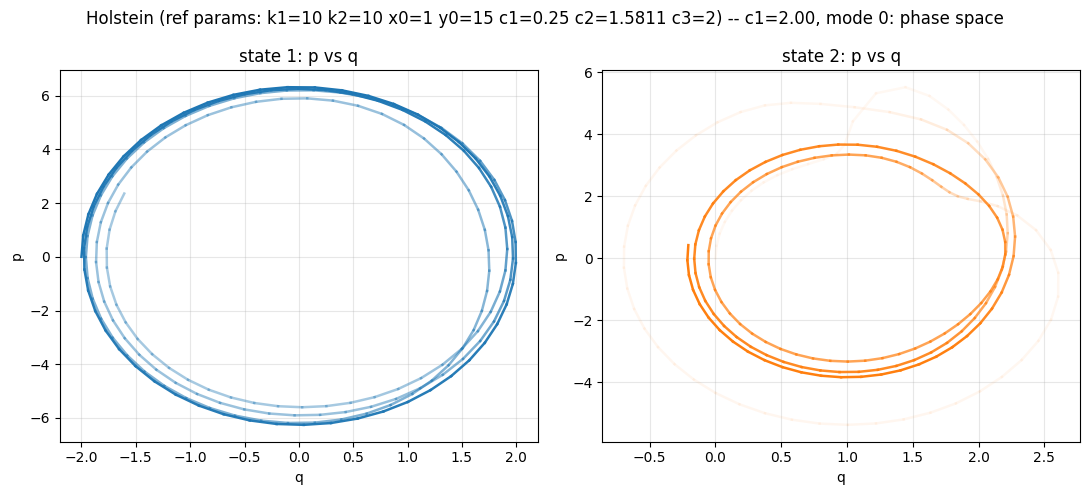

In [16]:
# Phase portrait p vs q for every state (uses `runs` and `mode` from the
# cell above).  Line opacity follows the state's population, so a seeded
# (nearly empty) state is faint until population arrives.
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

for label, r in runs:
    N = r["N"]
    pops = np.abs(r["c"]) ** 2 / np.sum(np.abs(r["c"]) ** 2, axis=1)[:, None]
    fig, ax = plt.subplots(1, N, figsize=(5.5 * N, 5), squeeze=False)
    for i in range(N):
        a_ = ax[0, i]
        qq, pp = r["q"][:, i, mode], r["p"][:, i, mode]
        w = np.clip(pops[:, i] / max(pops[:, i].max(), 1e-300), 0.05, 1.0)
        for n in range(len(qq) - 1):
            a_.plot(qq[n:n + 2], pp[n:n + 2], color=colors[i % len(colors)],
                    alpha=float(w[n]), lw=1.8)
        a_.set_xlabel("q"); a_.set_ylabel("p"); a_.grid(alpha=.3)
        a_.set_title("state %d: p vs q" % (i + 1))
    fig.suptitle("%s -- %s, mode %d: phase space" % (model["name"], label, mode))
    fig.tight_layout(); plt.show()

## 7. Seed sweep: uniform and shift, epsilon = 0.01, 0.02, 0.05 (Holstein)

`run_seed_sweep()` runs the Holstein case (case 3) for both seed modes

* **uniform**: `psi_1 = cos(eps) g_1`, `psi_2 = sin(eps) g_2` with `g_2` the
  Gaussian given for state 2 (Holstein: q = 0, coherent width),
* **shift**: `psi_2 = -i sin(eps) g_2`, `g_2` centred where the coupling puts
  it, `q_2 = (a_1 q_1 + 2 beta x_c)/(a_1 + 2 beta)`, with state 2's own
  coherent width,

every epsilon, and four kinds of dynamics:

| folder | widths | coupling terms (`drop_corrections`) |
|---|---|---|
| `thawed_vgwp` | thawed | with (0) |
| `thawed_no_coupling` | thawed | without (1) |
| `frozen_gwp` | frozen | with (0) |
| `frozen_no_coupling` | frozen | without (1) |

i.e. 2 x 3 x 4 = 24 runs, each saved in its own folder:

    holstein_seed_sweep/<uniform|shift>/eps_<eps>/<thawed_vgwp|thawed_no_coupling|frozen_gwp|frozen_no_coupling>/

Each run folder holds the usual `mdl.write_observables` files (summary,
observables -- with the `<V_c>` column --, energy at every step,
widths_full, q, p, a, coeff, wfc), plus

* `coupling.txt`: t, the coupling expectation value `<V_c>(t)` and
  Re/Im `<g_1|V_c|g_2>` (the element between the Gaussians, no c's),
* `exact.txt`: the exact TDSE from the same seeded initial state.

`holstein_seed_sweep/potential.txt` holds the potential once (it is the same
for every run): x, the two diabatic surfaces V1(x), V2(x) and the coupling
V_c(x).  `holstein_seed_sweep/sweep_summary.txt` has one row per run, including the
largest |<V_c>|.  Self-contained: it builds its own model, so it depends only
on the import cells.  Takes a few minutes.

In [17]:
def run_seed_sweep(epsilons=(0.01, 0.02, 0.05), outdir="holstein_seed_sweep",
                   case=3, seed_modes=("uniform", "shift")):
    """Holstein seed sweep: for every seed mode and epsilon, run

        thawed_vgwp          thawed widths, with coupling terms    (drop 0)
        thawed_no_coupling   thawed widths, without coupling terms (drop 1)
        frozen_gwp           frozen widths, with coupling terms    (drop 0)
        frozen_no_coupling   frozen widths, without coupling terms (drop 1)

    and save each run in its own folder

        outdir/<seed_mode>/eps_<eps>/<dynamics>/

    epsilon is the seed theta:
      seed_mode="uniform"  psi_1 = cos(eps) g_1,  psi_2 = sin(eps) g_2
                           (g_2 = the Gaussian given for state 2)
      seed_mode="shift"    psi_2 = -i sin(eps) g_2, g_2 at the coupling-shifted
                           centre with state 2's own coherent width
    Each folder gets the mdl.write_observables files (observables.txt has
    the <V_c> column), coupling.txt (t, <V_c>, Re/Im <g1|Vc|g2>) and exact.txt: the exact TDSE
    started from the SAME seeded psi_1(x,0), psi_2(x,0) as that run.
    outdir/sweep_summary.txt has one row per run, and outdir/potential.txt
    the two diabatic surfaces and the coupling on the grid (x, V1, V2, V_c).

    Returns the list of summary rows (dicts).
    """
    mp = mdl.model_params(case)
    hmodel = mdl.build_model(mp)
    kw = mp["kwargs"]
    base = mdl.dyn_params(case, mp)
    dynamics = (("thawed_vgwp", "thawed", 0),
                ("thawed_no_coupling", "thawed", 1),
                ("frozen_gwp", "frozen", 0),
                ("frozen_no_coupling", "frozen", 1))

    # exact split-operator reference, same window as the VGWP runs
    x, k, dx = compute.grid(-8.0, 8.0, 2048)
    v1 = 0.5 * kw["k1"] * x ** 2
    v2 = 0.5 * kw["k2"] * (x - kw["x0"]) ** 2 + kw["y0"]
    vc = kw["c1"] * np.exp(-kw["c2"] * (x - kw["c3"]) ** 2)
    dt_exact, nsteps_exact = mdl.exact_steps(base["t_max"], 0.0005)

    # the potential is the same for every run: save it once
    os.makedirs(outdir, exist_ok=True)
    mdl.write_table(os.path.join(outdir, "potential.txt"),
                    ["x", "V1", "V2", "V_c"], [x, v1, v2, vc],
                    title="%s: diabatic surfaces V1 = k1 x^2/2, "
                          "V2 = k2 (x-x0)^2/2 + y0 and coupling "
                          "V_c = c1 exp[-c2 (x-c3)^2]" % hmodel["name"])

    rows = []
    for sm in seed_modes:
        for eps in epsilons:
            for tag, wm, dc in dynamics:
                dyn = dict(base, seed=eps, seed_mode=sm,
                           drop_corrections=dc, width_mode=wm, energy_every=1)
                r = mdl.run_case(case, hmodel, dyn)

                psi1, psi2 = compute.reconstruct(r, 0, x)
                ex = compute.propagate_exact(psi1, psi2, x, k, kw["mass"],
                                             v1, v2, vc, dt_exact, nsteps_exact,
                                             record_every=100)

                sub = os.path.join(outdir, sm, "eps_%.2f" % eps, tag)
                mdl.write_observables(
                    r, sub, note="seed_mode=%s, eps=%g, %s (%s widths, "
                                 "drop_corrections=%d)" % (sm, eps, tag, wm, dc))
                mdl.write_table(os.path.join(sub, "coupling.txt"),
                                ["t", "<V_c>", "Re<g1|Vc|g2>", "Im<g1|Vc|g2>"],
                                [r["t"], r["coupling"],
                                 r["W"][:, 0, 1].real, r["W"][:, 0, 1].imag],
                                title="coupling: <V_c>(t) = sum_{i!=j} c_i^* c_j "
                                      "<g_i|V_ij|g_j> (with the c's) and the "
                                      "element <g_1|V_c|g_2> between the Gaussians")
                mdl.write_table(os.path.join(sub, "exact.txt"),
                                ["t", "|c1|^2_exact", "|c2|^2_exact",
                                 "norm_exact", "<x>_1", "<x>_2"],
                                [ex["t"], ex["pops"][:, 0], ex["pops"][:, 1],
                                 ex["norm"], ex["xmean"][:, 0], ex["xmean"][:, 1]],
                                title="exact split-operator reference from the "
                                      "same seeded initial state (seed_mode=%s, eps=%g)"
                                      % (sm, eps))

                P = np.interp(ex["t"], r["t"], r["pops"][:, 1])
                err = np.abs(P - ex["pops"][:, 1])
                row = dict(seed=sm, eps=eps, dyn=tag,
                           c2_vgwp=r["pops"][-1, 1], c2_exact=ex["pops"][-1, 1],
                           mean_err=err.mean(), max_err=err.max(),
                           vc_max=np.abs(r["coupling"]).max(),
                           dEmax=r["dEmax"], dNmax=r["dNmax"])
                rows.append(row)
                print("%-8s eps=%.2f %-19s final |c2|^2 %.4f (exact %.4f)  "
                      "mean|dP| %.4f  max|<Vc>| %.3f  dE %.1e  -> %s/"
                      % (sm, eps, tag, row["c2_vgwp"], row["c2_exact"],
                         row["mean_err"], row["vc_max"], row["dEmax"], sub))

    path = os.path.join(outdir, "sweep_summary.txt")
    with open(path, "w") as f:
        f.write("# %s -- seed sweep, t_max=%g, seed_modes=%s\n"
                % (hmodel["name"], base["t_max"], ",".join(seed_modes)))
        f.write("# %-8s %-6s %-19s %-14s %-14s %-14s %-14s %-14s %-14s %-14s\n"
                % ("seed", "eps", "dynamics", "|c2|^2_vgwp", "|c2|^2_exact",
                   "mean|dP|", "max|dP|", "max|<Vc>|", "dEmax", "dNmax"))
        for w in rows:
            f.write("  %-8s %-6.2f %-19s %-14.6e %-14.6e %-14.6e %-14.6e "
                    "%-14.6e %-14.6e %-14.6e\n"
                    % (w["seed"], w["eps"], w["dyn"], w["c2_vgwp"],
                       w["c2_exact"], w["mean_err"], w["max_err"],
                       w["vc_max"], w["dEmax"], w["dNmax"]))
    print("wrote %s" % path)
    return rows


#sweep = run_seed_sweep()

## 7b. Seed sweep for Tully I: uniform and shift, epsilon = 0.01, 0.02, 0.05

`run_tully_sweep()` is the same sweep for Tully model I (case 0: tanh
diabats, Gaussian coupling, packet from x0 = -5 with p0 = 10), for

* **uniform**: `psi_2 = sin(eps) g_2`, `g_2` = the Gaussian given for state 2
  (Tully: the same as state 1, i.e. a copy of `g_1`),
* **shift**: `psi_2 = -i sin(eps) g_2`, `g_2` centred where the coupling puts
  it (shifted toward the crossing) with the width given for state 2 in `Z0`
  (Tully: the same as `g_1`),

every epsilon and the same four kinds of dynamics (`thawed_vgwp`,
`thawed_no_coupling`, `frozen_gwp`, `frozen_no_coupling`): 2 x 3 x 4 = 24 runs in

    tully_seed_sweep/<uniform|shift>/eps_<eps>/<thawed_vgwp|thawed_no_coupling|frozen_gwp|frozen_no_coupling>/

each with the `mdl.write_observables` files, `coupling.txt` (t, `<V_c>`,
Re/Im `<g_1|V_c|g_2>`) and
`exact.txt` (split-operator TDSE from the same seeded state), plus
`tully_seed_sweep/potential.txt` (x, V11, V22, V12) and
`tully_seed_sweep/sweep_summary.txt`.

`dt = 0.05` by default (converged for Tully: 0.2 down to 0.02 give the same
populations).  Takes several minutes.

In [18]:
def run_tully_sweep(epsilons=(0.01, 0.02, 0.05), outdir="tully_seed_sweep",
                    case=0, seed_modes=("uniform", "shift"), dt=0.05):
    """Tully I seed sweep: for every seed mode and epsilon, run

        thawed_vgwp          thawed widths, with coupling terms    (drop 0)
        thawed_no_coupling   thawed widths, without coupling terms (drop 1)
        frozen_gwp           frozen widths, with coupling terms    (drop 0)
        frozen_no_coupling   frozen widths, without coupling terms (drop 1)

    and save each run in outdir/<seed_mode>/eps_<eps>/<dynamics>/ with the
    mdl.write_observables files, coupling.txt (t, <V_c>, Re/Im <g1|Vc|g2>) and exact.txt (the
    exact TDSE from the SAME seeded state).  outdir/potential.txt holds
    x, V11, V22, V12 and outdir/sweep_summary.txt one row per run.

    Returns the list of summary rows (dicts).
    """
    mp = mdl.model_params(case)
    tmodel = mdl.build_model(mp)
    kw = mp["kwargs"]
    base = dict(mdl.dyn_params(case, mp), dt=dt, dt_out=None,
                record_every=max(1, int(round(4.0 / dt))))
    mass = float(tmodel["mass"][0])
    dynamics = (("thawed_vgwp", "thawed", 0),
                ("thawed_no_coupling", "thawed", 1),
                ("frozen_gwp", "frozen", 0),
                ("frozen_no_coupling", "frozen", 1))

    # exact split-operator reference: window holds both branches up to t_max
    x, k, dx = compute.grid(-20.0, 25.0, 4096)
    v1, v2 = tmodel["vfun"][0](0, x), tmodel["vfun"][1](0, x)
    vc = kw["C"] * np.exp(-kw["D"] * x ** 2)
    dt_exact, nsteps_exact = mdl.exact_steps(base["t_max"], 0.05)

    # the potential is the same for every run: save it once
    os.makedirs(outdir, exist_ok=True)
    mdl.write_table(os.path.join(outdir, "potential.txt"),
                    ["x", "V11", "V22", "V12"], [x, v1, v2, vc],
                    title="%s: V11 = A(1+tanh Bx), V22 = A(1-tanh Bx), "
                          "V12 = C exp(-D x^2); A=%g B=%g C=%g D=%g"
                          % (tmodel["name"], kw["A"], kw["B"], kw["C"], kw["D"]))

    rows = []
    for sm in seed_modes:
        for eps in epsilons:
            for tag, wm, dc in dynamics:
                dyn = dict(base, seed=eps, seed_mode=sm,
                           drop_corrections=dc, width_mode=wm, energy_every=1)
                r = mdl.run_case(case, tmodel, dyn)

                psi1, psi2 = compute.reconstruct(r, 0, x)
                ex = compute.propagate_exact(psi1, psi2, x, k, mass,
                                             v1, v2, vc, dt_exact, nsteps_exact,
                                             record_every=80)

                sub = os.path.join(outdir, sm, "eps_%.2f" % eps, tag)
                mdl.write_observables(
                    r, sub, note="seed_mode=%s, eps=%g, %s (%s widths, "
                                 "drop_corrections=%d)" % (sm, eps, tag, wm, dc))
                mdl.write_table(os.path.join(sub, "coupling.txt"),
                                ["t", "<V_c>", "Re<g1|Vc|g2>", "Im<g1|Vc|g2>"],
                                [r["t"], r["coupling"],
                                 r["W"][:, 0, 1].real, r["W"][:, 0, 1].imag],
                                title="coupling: <V_c>(t) = sum_{i!=j} c_i^* c_j "
                                      "<g_i|V_ij|g_j> (with the c's) and the "
                                      "element <g_1|V_c|g_2> between the Gaussians")
                mdl.write_table(os.path.join(sub, "exact.txt"),
                                ["t", "|c1|^2_exact", "|c2|^2_exact",
                                 "norm_exact", "<x>_1", "<x>_2"],
                                [ex["t"], ex["pops"][:, 0], ex["pops"][:, 1],
                                 ex["norm"], ex["xmean"][:, 0], ex["xmean"][:, 1]],
                                title="exact split-operator reference from the "
                                      "same seeded initial state (seed_mode=%s, eps=%g)"
                                      % (sm, eps))

                P = np.interp(ex["t"], r["t"], r["pops"][:, 1])
                err = np.abs(P - ex["pops"][:, 1])
                row = dict(seed=sm, eps=eps, dyn=tag,
                           c2_vgwp=r["pops"][-1, 1], c2_exact=ex["pops"][-1, 1],
                           mean_err=err.mean(), max_err=err.max(),
                           vc_max=np.abs(r["coupling"]).max(),
                           dEmax=r["dEmax"], dNmax=r["dNmax"])
                rows.append(row)
                print("%-8s eps=%.2f %-19s final |c2|^2 %.4f (exact %.4f)  "
                      "mean|dP| %.4f  max|<Vc>| %.2e  dE %.1e  -> %s/"
                      % (sm, eps, tag, row["c2_vgwp"], row["c2_exact"],
                         row["mean_err"], row["vc_max"], row["dEmax"], sub))

    path = os.path.join(outdir, "sweep_summary.txt")
    with open(path, "w") as f:
        f.write("# %s -- seed sweep, dt=%g, t_max=%g, seed_modes=%s\n"
                % (tmodel["name"], dt, base["t_max"], ",".join(seed_modes)))
        f.write("# %-8s %-6s %-19s %-14s %-14s %-14s %-14s %-14s %-14s %-14s\n"
                % ("seed", "eps", "dynamics", "|c2|^2_vgwp", "|c2|^2_exact",
                   "mean|dP|", "max|dP|", "max|<Vc>|", "dEmax", "dNmax"))
        for w in rows:
            f.write("  %-8s %-6.2f %-19s %-14.6e %-14.6e %-14.6e %-14.6e "
                    "%-14.6e %-14.6e %-14.6e\n"
                    % (w["seed"], w["eps"], w["dyn"], w["c2_vgwp"],
                       w["c2_exact"], w["mean_err"], w["max_err"],
                       w["vc_max"], w["dEmax"], w["dNmax"]))
    print("wrote %s" % path)
    return rows



#tully_sweep = run_tully_sweep()

## 8. Seed sweep for the Coronado Morse model (case 8, model I)

`run_coronado_sweep()` runs the three-state Morse model for **three seed
modes** -- `uniform`, `shift`, `coupling` -- and for each, **with and without
the coupling corrections** in `qdot`, `pdot`, `Zdot` (`drop_corrections`
0 / 1), for both thawed and frozen widths:

| folder | widths | coupling terms (`drop_corrections`) |
|---|---|---|
| `thawed_vgwp` | thawed | with (0) |
| `thawed_no_coupling` | thawed | without (1) |
| `frozen_gwp` | frozen | with (0) |
| `frozen_no_coupling` | frozen | without (1) |

i.e. 3 seed modes x len(epsilons) x 4 = 36 runs with the default three
epsilons, saved as

    coronado_seed_sweep/<uniform|shift|coupling>/eps_<eps>/<dynamics>/

Each run folder holds the usual `mdl.write_observables` files plus
`coupling.txt` (t, `<V_c>`, and Re/Im of the three `<g_i|V_ij|g_j>`), and
`exact.txt`, the exact three-state SOFT propagation started from the SAME
seeded state.  That reference depends only on the seed mode and epsilon, not
on the dynamics, so it is computed once per (mode, eps) and written into each
of that group's four folders.  `coronado_seed_sweep/potential.txt` holds the
three Morse diabats and the couplings on the grid, and `sweep_summary.txt`
one row per run: final populations, the largest deviation from exact, the
energy and norm drift and the largest `|<V_c>|`.

Two knobs matter most here (see `mdl.dyn_params`, case 8): `seed_track`,
which this model needs for any transfer at all, and the seed itself, which
also sets the release threshold `track_factor * sin^2(seed)`.  Takes several
minutes.

In [19]:
def run_coronado_sweep(epsilons=(1e-3, 3e-3, 1e-2), outdir="coronado_seed_sweep",
                       case=8, variant=1, seed_track=True,
                       seed_modes=("uniform", "shift", "coupling")):
    """Coronado three-state Morse sweep: seed mode x epsilon x dynamics.

        thawed_vgwp          thawed widths, with coupling terms    (drop 0)
        thawed_no_coupling   thawed widths, without coupling terms (drop 1)
        frozen_gwp           frozen widths, with coupling terms    (drop 0)
        frozen_no_coupling   frozen widths, without coupling terms (drop 1)

    saved in outdir/<seed_mode>/eps_<eps>/<dynamics>/.  The exact SOFT
    reference depends only on the seeded initial state, so it is computed once
    per (seed_mode, eps) and written into that group's four folders.

    Returns the list of summary rows (dicts).
    """
    mp = mdl.model_params(case)
    mp["kwargs"]["variant"] = variant
    cmodel = mdl.build_model(mp)
    base = dict(mdl.dyn_params(case, mp), seed_track=seed_track, energy_every=1)
    N = cmodel["N"]
    dynamics = (("thawed_vgwp", "thawed", 0),
                ("thawed_no_coupling", "thawed", 1),
                ("frozen_gwp", "frozen", 0),
                ("frozen_no_coupling", "frozen", 1))

    axes = [np.linspace(0.5, 30.0, 4096, endpoint=False)]
    x = axes[0]
    dt_exact = 0.5
    nsteps_exact = int(round(base["t_max"] / dt_exact))
    dt_out = base.get("dt_out") or base["record_every"] * base["dt"]
    rec_exact = max(1, int(round(dt_out / dt_exact)))

    os.makedirs(outdir, exist_ok=True)
    Vx = compute.potential_matrix(cmodel, x[:, None])
    mdl.write_table(os.path.join(outdir, "potential.txt"),
                    ["x"] + ["V%d%d" % (i + 1, i + 1) for i in range(N)]
                    + ["V12", "V13", "V23"],
                    [x] + [Vx[:, i, i] for i in range(N)]
                    + [Vx[:, 0, 1], Vx[:, 0, 2], Vx[:, 1, 2]],
                    title="%s: Morse diabats and Gaussian couplings" % cmodel["name"])

    rows = []
    for sm in seed_modes:
        for eps in epsilons:
            # the seeded state at t=0 is the same for all four dynamics
            seeded = mdl.run_case(case, cmodel,
                                  dict(base, seed=eps, seed_mode=sm, t_max=0.0,
                                       dt_out=None, record_every=1))
            psi0 = np.array(compute.reconstruct(seeded, 0, x[:, None]))
            ex = compute.propagate_exact_grid(cmodel, psi0, axes, dt_exact,
                                              nsteps_exact, record_every=rec_exact)
            for tag, wm, dc in dynamics:
                dyn = dict(base, seed=eps, seed_mode=sm,
                           drop_corrections=dc, width_mode=wm)
                try:
                    r = mdl.run_case(case, cmodel, dyn)
                except Exception as err:
                    print("  %-8s eps=%-7g %-20s FAILED: %s"
                          % (sm, eps, tag, type(err).__name__))
                    rows.append(dict(seed_mode=sm, eps=eps, dynamics=tag,
                                     failed=type(err).__name__))
                    continue
                P = np.array([np.interp(ex["t"], r["t"], r["pops"][:, i])
                              for i in range(N)]).T
                sub = os.path.join(outdir, sm, "eps_%g" % eps, tag)
                mdl.write_observables(
                    r, sub, note="seed_mode=%s, eps=%g, %s (%s widths, "
                                 "drop_corrections=%d, seed_track=%s)"
                                 % (sm, eps, tag, wm, dc, seed_track))
                W = r["W"]
                mdl.write_table(os.path.join(sub, "coupling.txt"),
                                ["t", "<V_c>", "ReW12", "ImW12", "ReW13",
                                 "ImW13", "ReW23", "ImW23"],
                                [r["t"], r["coupling"],
                                 W[:, 0, 1].real, W[:, 0, 1].imag,
                                 W[:, 0, 2].real, W[:, 0, 2].imag,
                                 W[:, 1, 2].real, W[:, 1, 2].imag],
                                title="coupling energy <V_c>(t) and <g_i|V_ij|g_j>")
                mdl.write_table(os.path.join(sub, "exact.txt"),
                                ["t"] + ["P%d_exact" % (i + 1) for i in range(N)],
                                [ex["t"]] + [ex["pops"][:, i] for i in range(N)],
                                title="exact SOFT from the same seeded state")
                row = dict(seed_mode=sm, eps=eps, dynamics=tag, widths=wm,
                           drop=dc, dE=r["dEmax"], dN=r["dNmax"],
                           maxVc=float(np.max(np.abs(r["coupling"]))),
                           err=float(np.max(np.abs(P - ex["pops"]))))
                for i in range(N):
                    row["P%d" % (i + 1)] = float(r["pops"][-1, i])
                    row["P%d_exact" % (i + 1)] = float(ex["pops"][-1, i])
                rows.append(row)
                print("  %-8s eps=%-7g %-20s final %s  err %.3f  dE %.0e dN %.0e"
                      % (sm, eps, tag, np.round(r["pops"][-1], 3), row["err"],
                         r["dEmax"], r["dNmax"]))

    # mdl.write_table takes numeric columns only, and this summary mixes text
    # with numbers, so it is written directly.
    names = (["seed_mode", "eps", "dynamics", "widths", "drop"]
             + ["P%d" % (i + 1) for i in range(N)]
             + ["P%d_exact" % (i + 1) for i in range(N)]
             + ["err", "dE", "dN", "maxVc"])
    ok = [r for r in rows if "failed" not in r]
    fmt = lambda v: ("%-20s" % v) if isinstance(v, str) else ("%-20.6g" % v)
    lines = ["# %s: one row per run (err = max|P - P_exact|)" % cmodel["name"],
             "# " + "".join("%-20s" % n for n in names)]
    for r in ok:
        lines.append("  " + "".join(fmt(r[n]) for n in names))
    for r in [r for r in rows if "failed" in r]:
        lines.append("  %-20s%-20g%-20s%s" % (r["seed_mode"], r["eps"],
                                              r["dynamics"], "FAILED: " + r["failed"]))
    with open(os.path.join(outdir, "sweep_summary.txt"), "w") as fh:
        fh.write("\n".join(lines) + "\n")
    print("wrote %s/ (%d runs)" % (outdir, len(ok)))
    return rows

#rows_coronado = run_coronado_sweep()

Run it (several minutes).  Cut `epsilons` or `seed_modes` down for a quick
look, e.g. `run_coronado_sweep(epsilons=(3e-3,), seed_modes=("uniform",))`.

## 8. Timestep convergence: total energy

`energy_convergence()` reruns the current `case` / `dyn_params` at each time
step `dt` and prints a table of max|E(t) - E0| over the run.  The output step
`dt_out` is kept the same for every dt (default: the base run's), so every
`dt` in the list must divide it.  `ratio` is how many times smaller the drift
is than at the previous (larger) dt: about 16 per halving for RK4.  A ratio
that stops growing means a dt-independent floor -- e.g. `eps` in
1/(|c|^2 + eps), or `drop_corrections=1`, which does not conserve energy at all.

`energy_every=1` checks the energy at EVERY step, not only at the saved frames.

In [20]:
def energy_convergence(case, model, dyn_params, dts, dt_out=None):
    """Table of total-energy conservation vs time step dt, at a fixed output
    step dt_out (default: the base run's dt_out, or dt * record_every)."""
    dts = sorted(dts, reverse=True)
    if dt_out is None:
        dt_out = dyn_params.get("dt_out") or dyn_params["dt"] * dyn_params["record_every"]
    print("t_max = %g, dt_out = %g" % (dyn_params["t_max"], dt_out))
    print("%-10s %-10s %-14s %-8s" % ("dt", "nsteps", "max|E-E0|", "ratio"))
    prev = None
    rows = []
    for dt in dts:
        r = mdl.run_case(case, model, dyn_params, dt=dt, dt_out=dt_out,
                         energy_every=1)
        ratio = "" if prev is None else "%.1f" % (prev / r["dEmax"])
        print("%-10g %-10d %-14.2e %-8s"
              % (dt, round(dyn_params["t_max"] / dt), r["dEmax"], ratio))
        prev = r["dEmax"]
        rows.append((dt, r["dEmax"]))
    return rows

In [21]:
# Pick dts that divide dt_out.  Holstein (case 3): dt_out = 0.02 by default.
# Tully (case 0): e.g. [0.4, 0.2, 0.1, 0.05] with dt_out = 0.4.
if case == 3:
    econv = energy_convergence(case, model, dyn_params, [0.004, 0.002, 0.001, 0.0005])
elif case == 0:
    econv = energy_convergence(case, model, dyn_params, [0.4, 0.2, 0.1, 0.05], dt_out=0.4)

## 9. Paper figure: panels B and C (Holstein)

Reproduces the two VGWP panels of the reference figure with **frozen** widths
and the coupling terms (`drop_corrections = 0`), `eps = 0.01`:

| panel | label | our settings |
|---|---|---|
| B | `psi_2 = eps psi_1` | `seed_mode="uniform"`, `q0 = [[-2], [-2]]` (copy of `g_1`) |
| C | `psi_2 = eps V_c psi_1` | `seed_mode="uniform"`, `q0 = [[-2], [0]]` (shifted centre, coherent width) |

Panel C as plotted uses the V_c-shifted **centre** with the **coherent** width
(the reference Fortran `IN` with `init_WF = 0`, `q2 = 0`, `a2 = 3.162`), not the
narrower width of V_c psi_1 itself (`seed_mode="coupling"`, which ends at
P2 = 0.23 with frozen widths).  Top row: `<x>` (centre q) of state 1 (black)
and state 2 (red, dashed); bottom row: populations.  Self-contained: it builds
its own model.

## 9. RMS energy error of every sweep run

Energy is a conserved quantity of the exact TDVP flow, so the natural error
measure for a run is the deviation of `E(t)` from its initial value, over the
M recorded steps:

$$\mathrm{RMSE}_E=\sqrt{\frac{1}{M}\sum_{m=1}^{M}\big[E(t_m)-E(0)\big]^2}$$

reported in atomic units and relative to `|E(0)|`, beside `max|E - E0|` (the
`dEmax` the propagator already tracks) and the same RMS measure for the norm.

`energy_rmse()` reads `<sweep>/<seed_mode>/eps_<eps>/<dynamics>/energy.txt`,
which `mdl.write_observables` writes with the columns t, energy, energy-E0,
norm, norm-norm0 at every checked step (set `energy_every=1` in the sweep to
get every step).  It writes `energy_rmse.txt` into each sweep directory and a
combined `sweep_energy_rmse.txt`, and returns the rows as a list of dicts.

With no argument it discovers every directory whose name contains `sweep` and
that holds at least one `energy.txt`, i.e. the Holstein, Tully and Coronado
sweeps of the cells above.  The same code is in `examples/energy_rmse.py`, to
run from a shell.

In [22]:
def energy_rmse(sweeps=None, combined="sweep_energy_rmse.txt", quiet=False):
    """RMS energy error of every run in each sweep directory.

        RMSE_E = sqrt( (1/M) sum_m [E(t_m) - E(0)]^2 )

    sweeps : list of directories, or None to discover every "*sweep*" folder
             holding an energy.txt.
    Writes <sweep>/energy_rmse.txt and `combined`; returns the rows.
    """
    def discover():
        out = []
        for d in sorted(os.listdir(".")):
            if os.path.isdir(d) and "sweep" in d:
                for _root, _dirs, files in os.walk(d):
                    if "energy.txt" in files:
                        out.append(d)
                        break
        return out

    def rows_of(sweep):
        rows = []
        for mode in sorted(os.listdir(sweep)):
            mdir = os.path.join(sweep, mode)
            if not os.path.isdir(mdir):
                continue
            for epsd in sorted(os.listdir(mdir)):
                edir = os.path.join(mdir, epsd)
                if not os.path.isdir(edir):
                    continue
                for dyn in sorted(os.listdir(edir)):
                    path = os.path.join(edir, dyn, "energy.txt")
                    if not os.path.isfile(path):
                        continue
                    d = np.loadtxt(path)
                    if d.ndim == 1:
                        d = d[None, :]
                    t, E, dE, nrm, dN = (d[:, i] for i in range(5))
                    E0 = E[0]
                    rows.append(dict(sweep=sweep, seed_mode=mode,
                                     eps=epsd.replace("eps_", ""), dynamics=dyn,
                                     M=len(t), E0=E0,
                                     rmse=float(np.sqrt(np.mean(dE ** 2))),
                                     rel=float(np.sqrt(np.mean(dE ** 2)) / abs(E0))
                                     if E0 else np.nan,
                                     dmax=float(np.max(np.abs(dE))),
                                     rmse_n=float(np.sqrt(np.mean(dN ** 2)))))
        return rows

    head = ("# %-28s %-10s %-8s %-20s %7s %14s %13s %13s %13s %13s"
            % ("sweep", "seed_mode", "eps", "dynamics", "M", "E0", "RMSE_E",
               "RMSE_E/|E0|", "max|E-E0|", "RMSE_norm"))
    fmt = lambda r: ("  %-28s %-10s %-8s %-20s %7d %14.8e %13.6e %13.6e %13.6e %13.6e"
                     % (r["sweep"], r["seed_mode"], r["eps"], r["dynamics"],
                        r["M"], r["E0"], r["rmse"], r["rel"], r["dmax"], r["rmse_n"]))
    note = ("# RMS energy error per run: "
            "RMSE_E = sqrt(mean_m [E(t_m) - E(0)]^2), atomic units")

    allrows = []
    for sweep in (sweeps if sweeps is not None else discover()):
        rows = rows_of(sweep)
        if not rows:
            continue
        with open(os.path.join(sweep, "energy_rmse.txt"), "w") as fh:
            fh.write(note + "\n" + head + "\n"
                     + "\n".join(fmt(r) for r in rows) + "\n")
        if not quiet:
            print("wrote %s/energy_rmse.txt  (%d runs)" % (sweep, len(rows)))
        allrows += rows
    if allrows and combined:
        with open(combined, "w") as fh:
            fh.write(note + "\n" + head + "\n"
                     + "\n".join(fmt(r) for r in allrows) + "\n")
        if not quiet:
            print("wrote %s  (%d runs total)" % (combined, len(allrows)))
    return allrows


rows_rmse = energy_rmse()

# summary by sweep and dynamics
by = {}
for r in rows_rmse:
    by.setdefault((r["sweep"], r["dynamics"]), []).append(r["rmse"])
print("\n%-30s %-20s %5s %12s %12s" % ("sweep", "dynamics", "runs", "RMSE min", "RMSE max"))
for k in sorted(by):
    print("%-30s %-20s %5d %12.3e %12.3e"
          % (k[0], k[1], len(by[k]), min(by[k]), max(by[k])))

wrote coronado_seed_sweep/energy_rmse.txt  (36 runs)
wrote holstein_seed_sweep/energy_rmse.txt  (24 runs)
wrote holstein_seed_sweep_coupling/energy_rmse.txt  (12 runs)
wrote tully_seed_sweep/energy_rmse.txt  (24 runs)
wrote sweep_energy_rmse.txt  (96 runs total)

sweep                          dynamics              runs     RMSE min     RMSE max
coronado_seed_sweep            frozen_gwp               9    5.148e-08    4.207e-06
coronado_seed_sweep            frozen_no_coupling       9    1.940e-06    1.431e-03
coronado_seed_sweep            thawed_no_coupling       9    6.006e-05    6.701e-04
coronado_seed_sweep            thawed_vgwp              9    3.739e-07    1.269e-05
holstein_seed_sweep            frozen_gwp               6    1.581e-10    3.770e-09
holstein_seed_sweep            frozen_no_coupling       6    1.185e-02    1.718e-01
holstein_seed_sweep            thawed_no_coupling       6    1.185e-02    1.718e-01
holstein_seed_sweep            thawed_vgwp              6    1.7

## 10. RK4 steps and propagated time of every sweep run

Separate from the energy-error cell above.  Each run folder's `summary.txt`
records `dt` and `t_max`, so for every run

    RK4 steps = round(t_max / dt)        (4 rhs evaluations per step)
    rhs calls = 4 * steps
    time      = t_max  atomic units  =  t_max * FS  femtoseconds

`run_steps()` collects those for every run of every sweep and writes
`run_steps.txt` into each sweep directory plus a combined
`sweep_run_steps.txt`.  Wall-clock is not stored by the sweeps, so with
`calibrate=True` it times a short (200-step) propagation of the matching
notebook case for each distinct (model, `width_mode`, `drop_corrections`) and
multiplies by the step count -- that column is an estimate, `est_wall_s`;
every other column is read from file.  The same code is in
`examples/run_steps.py` to run from a shell.

In [23]:
def run_steps(sweeps=None, calibrate=False, nsteps_cal=200,
              combined="sweep_run_steps.txt", quiet=False):
    """RK4 step count and propagated time of every run in each sweep.

        steps = round(t_max / dt),  rhs calls = 4 * steps,
        time  = t_max (a.u.) = t_max * initialize.FS (fs)

    calibrate=True adds est_wall_s, from a timed nsteps_cal-step run of the
    matching notebook case (case 3 Holstein, 0 Tully, 8 Coronado).
    Returns the rows as a list of dicts.
    """
    CASE_OF = {"holstein": 3, "tully": 0, "coronado": 8}

    def discover():
        out = []
        for d in sorted(os.listdir(".")):
            if os.path.isdir(d) and "sweep" in d:
                for _root, _dirs, files in os.walk(d):
                    if "summary.txt" in files:
                        out.append(d)
                        break
        return out

    def read_summary(path):
        out = {}
        for line in open(path):
            if line.startswith("#") or not line.strip():
                continue
            parts = line.split()
            for key in ("dt", "t_max", "frames", "width_mode", "drop_corr",
                        "states", "modes"):
                if parts[0] == key:
                    out[key] = parts[-1]
        return out

    def rows_of(sweep):
        rows = []
        for mode in sorted(os.listdir(sweep)):
            mdir = os.path.join(sweep, mode)
            if not os.path.isdir(mdir):
                continue
            for epsd in sorted(os.listdir(mdir)):
                edir = os.path.join(mdir, epsd)
                if not os.path.isdir(edir):
                    continue
                for dyn in sorted(os.listdir(edir)):
                    path = os.path.join(edir, dyn, "summary.txt")
                    if not os.path.isfile(path):
                        continue
                    s = read_summary(path)
                    dt, tmax = float(s["dt"]), float(s["t_max"])
                    rows.append(dict(sweep=sweep, seed_mode=mode,
                                     eps=epsd.replace("eps_", ""), dynamics=dyn,
                                     N=int(s["states"]), D=int(s["modes"]),
                                     width_mode=s["width_mode"],
                                     drop=int(s["drop_corr"]), dt=dt, t_max=tmax,
                                     steps=int(round(tmax / dt)),
                                     frames=int(s["frames"])))
        return rows

    def add_wall(rows):
        cost = {}
        for r in rows:
            fam = next((k for k in CASE_OF if k in r["sweep"]), None)
            key = (fam, r["width_mode"], r["drop"])
            if fam is None or key in cost:
                continue
            mp = mdl.model_params(CASE_OF[fam])
            m = mdl.build_model(mp)
            dyn = dict(mdl.dyn_params(CASE_OF[fam], mp), width_mode=r["width_mode"],
                       drop_corrections=r["drop"], dt=r["dt"],
                       t_max=nsteps_cal * r["dt"], dt_out=None,
                       record_every=nsteps_cal)
            t0 = time.time()
            compute.run(m, **dyn)
            cost[key] = (time.time() - t0) / nsteps_cal
        for r in rows:
            fam = next((k for k in CASE_OF if k in r["sweep"]), None)
            r["est_wall_s"] = cost.get((fam, r["width_mode"], r["drop"]),
                                       float("nan")) * r["steps"]

    cols = ["sweep", "seed_mode", "eps", "dynamics", "N", "D", "width_mode",
            "drop", "dt", "steps", "rhs_calls", "t_max_au", "t_max_fs", "frames"]
    if calibrate:
        cols.append("est_wall_s")
    W = {"sweep": 30, "seed_mode": 11, "eps": 8, "dynamics": 21, "N": 3, "D": 3,
         "width_mode": 9, "drop": 6}
    wid = lambda c: W.get(c, 13)
    head = "# " + "".join("%-*s" % (wid(c), c) for c in cols)
    note = ("# RK4 steps and propagated time per run; steps = round(t_max/dt), "
            "4 rhs calls each")

    def fmt(r):
        v = dict(r, rhs_calls=4 * r["steps"], t_max_au=r["t_max"],
                 t_max_fs=r["t_max"] * initialize.FS)
        return "  " + "".join(("%-*s" % (wid(c), v[c])) if isinstance(v[c], str)
                              else ("%-*.6g" % (wid(c), v[c])) for c in cols)

    allrows = []
    for sweep in (sweeps if sweeps is not None else discover()):
        rows = rows_of(sweep)
        if not rows:
            continue
        if calibrate:
            add_wall(rows)
        with open(os.path.join(sweep, "run_steps.txt"), "w") as fh:
            fh.write(note + "\n" + head + "\n"
                     + "\n".join(fmt(r) for r in rows) + "\n")
        if not quiet:
            print("wrote %s/run_steps.txt  (%d runs, %d RK4 steps)"
                  % (sweep, len(rows), sum(r["steps"] for r in rows)))
        allrows += rows
    if allrows and combined:
        with open(combined, "w") as fh:
            fh.write(note + "\n" + head + "\n"
                     + "\n".join(fmt(r) for r in allrows) + "\n")
        if not quiet:
            print("wrote %s  (%d runs, %g RK4 steps total)"
                  % (combined, len(allrows), sum(r["steps"] for r in allrows)))
    return allrows


rows_steps = run_steps()          # run_steps(calibrate=True) adds est_wall_s

# totals per sweep
tot = {}
for r in rows_steps:
    t = tot.setdefault(r["sweep"], [0, 0, 0.0])
    t[0] += 1
    t[1] += r["steps"]
    t[2] = r["t_max"]
print("\n%-30s %6s %14s %14s %12s" % ("sweep", "runs", "steps/run", "steps total", "t_max (au)"))
for k in sorted(tot):
    n, st, tm = tot[k]
    print("%-30s %6d %14d %14d %12g" % (k, n, st // n, st, tm))

wrote coronado_seed_sweep/run_steps.txt  (36 runs, 864000 RK4 steps)
wrote holstein_seed_sweep/run_steps.txt  (24 runs, 192000 RK4 steps)
wrote holstein_seed_sweep_coupling/run_steps.txt  (12 runs, 96000 RK4 steps)
wrote tully_seed_sweep/run_steps.txt  (24 runs, 960000 RK4 steps)
wrote sweep_run_steps.txt  (96 runs, 2.112e+06 RK4 steps total)

sweep                            runs      steps/run    steps total   t_max (au)
coronado_seed_sweep                36          24000         864000         3000
holstein_seed_sweep                24           8000         192000            8
holstein_seed_sweep_coupling       12           8000          96000            8
tully_seed_sweep                   24          40000         960000         2000


## 11. When each seeded state reaches the release threshold

A state seeded with angle `eps` starts with population `sin^2(eps)` and is
slaved to its donor until

    n_j(t) > track_factor * sin^2(eps)        (track_factor = 3 by default)

`release_times()` reports, for every run of a sweep, the time at which each
initially empty state first crosses that threshold.  The release times are not
written by `mdl.write_observables`, so they are reconstructed from
`observables.txt`: the first frame whose `|c_j|^2` exceeds the threshold, with
linear interpolation between frames (resolution = `dt_out`).  Writes
`release_times.txt` into the sweep directory and returns the rows.

In [24]:
def release_times(sweep="coronado_seed_sweep", track_factor=3.0, quiet=False):
    """Threshold-crossing time of every seeded state, for every run in `sweep`.

    threshold = track_factor * sin^2(eps);  the crossing time is interpolated
    between the two frames that bracket it.  Returns a list of dicts and
    writes <sweep>/release_times.txt.
    """
    rows = []
    for mode in sorted(os.listdir(sweep)):
        mdir = os.path.join(sweep, mode)
        if not os.path.isdir(mdir):
            continue
        for epsd in sorted(os.listdir(mdir)):
            edir = os.path.join(mdir, epsd)
            if not os.path.isdir(edir):
                continue
            eps = float(epsd.replace("eps_", ""))
            thr = track_factor * np.sin(eps) ** 2
            for dyn in sorted(os.listdir(edir)):
                path = os.path.join(edir, dyn, "observables.txt")
                if not os.path.isfile(path):
                    continue
                names = None
                for line in open(path):
                    if line.startswith("# t "):
                        names = line[1:].split()
                        break
                d = np.loadtxt(path)
                t = d[:, 0]
                row = dict(seed_mode=mode, eps=eps, dynamics=dyn, thr=thr)
                for j, nm in enumerate(names):
                    if not (nm.startswith("|c") and nm.endswith("|^2")):
                        continue
                    state = int(nm[2:-3])
                    pop = d[:, j]
                    if pop[0] > thr:                 # started above: never slaved
                        row["t%d" % state] = 0.0
                        continue
                    above = np.flatnonzero(pop > thr)
                    if len(above) == 0:
                        row["t%d" % state] = np.nan  # never released
                        continue
                    k = above[0]
                    t0, t1, p0, p1 = t[k - 1], t[k], pop[k - 1], pop[k]
                    row["t%d" % state] = (t0 + (thr - p0) * (t1 - t0) / (p1 - p0)
                                          if p1 != p0 else t1)
                    row["final%d" % state] = pop[-1]
                rows.append(row)

    states = sorted({int(k[1:]) for r in rows for k in r if k.startswith("t")
                     and k[1:].isdigit()})
    head = ("# %-10s %-8s %-20s %12s" % ("seed_mode", "eps", "dynamics", "threshold")
            + "".join("%14s" % ("t_release_%d" % s) for s in states)
            + "".join("%12s" % ("final_P%d" % s) for s in states))
    def fmt(r):
        return ("  %-10s %-8g %-20s %12.4e" % (r["seed_mode"], r["eps"],
                                               r["dynamics"], r["thr"])
                + "".join("%14.4g" % r.get("t%d" % s, np.nan) for s in states)
                + "".join("%12.4f" % r.get("final%d" % s, np.nan) for s in states))
    with open(os.path.join(sweep, "release_times.txt"), "w") as fh:
        fh.write("# release time = first t with n_j(t) > %g sin^2(eps), "
                 "interpolated between frames\n" % track_factor)
        fh.write(head + "\n" + "\n".join(fmt(r) for r in rows) + "\n")
    if not quiet:
        print("wrote %s/release_times.txt  (%d runs)\n" % (sweep, len(rows)))
        print(head)
        for r in rows:
            print(fmt(r))
    return rows


rows_release = release_times()

wrote coronado_seed_sweep/release_times.txt  (36 runs)

# seed_mode  eps      dynamics                threshold   t_release_1   t_release_2   t_release_3    final_P1    final_P2    final_P3
  coupling   0.001    frozen_gwp             3.0000e-06             0         12.39          1433         nan      0.2406      0.1765
  coupling   0.001    frozen_no_coupling     3.0000e-06             0         12.42           nan         nan      0.0002         nan
  coupling   0.001    thawed_no_coupling     3.0000e-06             0         12.41          2658         nan      0.0055      0.0001
  coupling   0.001    thawed_vgwp            3.0000e-06             0         12.38          1505         nan      0.2166      0.1409
  coupling   0.003    frozen_gwp             2.7000e-05             0         37.98          1524         nan      0.2324      0.1784
  coupling   0.003    frozen_no_coupling     2.7000e-05             0         37.81           nan         nan      0.0004         nan
  coup